# Machine Learning for Membrane Development

This tutorial presents a practical workflow for machine learning–based membrane performance modeling using a literature-derived dataset that links fabrication conditions to separation performance. The accompanying notebook demonstrates data loading, domain-informed feature engineering, supervised learning with tree-based models, post hoc model interpretation, and inverse design via Bayesian optimization.

The objectives are twofold: (i) to construct predictive models for permeability and rejection and (ii) to identify fabrication and solute descriptors that most strongly influence transport behavior. The workflow is intended as a hands-on complement to broader discussions of machine-learning-enabled membrane development and materials discovery.

## Section 0. Setup

This section imports the core Python packages used throughout the notebook and defines shared configuration settings to ensure reproducibility. Consistent plotting defaults are also specified so that figures share a common visual style and can be compared across sections.

Key tools used in this tutorial include:
- `pandas` and `numpy` for data handling,
- `scikit-learn` for preprocessing, model training, and evaluation,
- `shap` for model interpretation,
- `Ax` for inverse design in the final section.

If Ax or its dependencies are not available, Sections 1–5 can still be executed. Only the inverse-design section relies on Ax, so readers can focus on the core regression and interpretation workflow first.

In [ ]:
# For file handling and data manipulation
import os
import joblib
import numpy as np
import pandas as pd
import sys
import warnings

# For YAML configuration loading
try:
    import yaml
except ImportError:
    import subprocess
    print("Installing PyYAML...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "pyyaml"])
    import yaml

# For modeling and evaluation
from sklearn.model_selection import train_test_split, KFold, RandomizedSearchCV
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# For SHAP explanations (optional here; required later in SHAP section)
import shap
import matplotlib.pyplot as plt
import seaborn as sns

# For inverse design (Ax is optional until Section 6)
try:
    from ax.api.client import Client
    from ax.api.configs import RangeParameterConfig, ChoiceParameterConfig
except Exception as exc:
    Client = None
    RangeParameterConfig = None
    ChoiceParameterConfig = None
    warnings.warn(
        f"Ax import skipped during setup: {exc}. "
        "You can still run Sections 1-5; fix Ax/PyTorch before Section 6.",
        RuntimeWarning,
    )

# ============================================================================
# CONFIGURATION SETUP: Load all settings from config.yaml
# ============================================================================

# Navigate to project root and add src to path for config_loader
PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))
CODE_PATH = os.path.join(PROJECT_ROOT, "src")

if CODE_PATH not in sys.path:
    sys.path.insert(0, CODE_PATH)
    print(f"Added {CODE_PATH} to sys.path for module imports.")

# Load configuration from YAML file
from config_loader import load_config, get_data_paths, get_model_dir, get_figures_dir, get_plotting_config

config = load_config(project_root=PROJECT_ROOT)
print(f"\nConfiguration loaded from: {config['_config_path']}")

# ============================================================================
# PLOTTING CONFIGURATION
# ============================================================================

plotting_cfg = config["plotting"]

# Extract and apply plotting settings
FONT_SIZE = plotting_cfg["font_size"]
FIG_SIZE = tuple(plotting_cfg["global_figure_size"])
DPI = plotting_cfg["dpi"]

# Apply matplotlib settings
plt.rcParams["font.size"] = FONT_SIZE
plt.rcParams["figure.figsize"] = FIG_SIZE
plt.rcParams["savefig.dpi"] = DPI

# Nicer plot defaults
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Ellipse, Rectangle

sns.set(style="whitegrid", context="talk")

# Create custom colormap from config
colormap_cfg = plotting_cfg["custom_colormap"]
custom_cmap = LinearSegmentedColormap.from_list(
    colormap_cfg["name"],
    colormap_cfg["colors"]
)

print(f"Plotting config applied: FIG_SIZE={FIG_SIZE}, FONT_SIZE={FONT_SIZE}, DPI={DPI}")

# ============================================================================
# MODELING CONFIGURATION
# ============================================================================

RANDOM_STATE = config["modeling"]["random_state"]
np.random.seed(RANDOM_STATE)

# ============================================================================
# DATA PATHS (from config)
# ============================================================================

data_paths = get_data_paths(config)
DATA_PATH = data_paths["tutorial_dataset"]
CATION_PROP_PATH = data_paths["cation_prop"]
ANION_PROP_PATH = data_paths["anion_prop"]
MODEL_PATH = get_model_dir(config)
FIGURES_DIR = get_figures_dir(config)

# Ensure output directories exist
os.makedirs(FIGURES_DIR, exist_ok=True)

print(f"Data paths configured:")
print(f"  - Tutorial dataset: {os.path.basename(DATA_PATH)}")
print(f"  - Models directory: {MODEL_PATH}")
print(f"  - Figures output: {FIGURES_DIR}")


Added c:\GITHUB_NEW\ML-MEM-Review\src to sys.path for module imports.

??Configuration loaded from: c:\GITHUB_NEW\ML-MEM-Review\config.yaml
??Plotting config applied: FIG_SIZE=(14, 10), FONT_SIZE=20, DPI=300
??Data paths configured:
  - Tutorial dataset: TutorialDataSet.xlsx
  - Models directory: c:\GITHUB_NEW\ML-MEM-Review\models
  - Figures output: c:\GITHUB_NEW\ML-MEM-Review\outputs/figures


## Section 1. Raw Dataset Loading and Overview

This section loads the literature-curated membrane dataset. Each row corresponds to a single membrane formulation–performance record extracted from published studies, comprising both fabrication details and separation performance metrics.

The full dataset contains 278 rows and 36 columns. Representative column groups include:
- bibliographic identifiers such as `DOI` and `Source_literature`,
- fabrication descriptors such as `Dope1_Monomer1_Name`, `Dope1_Monomer1_Mass`, and `Dope2_Polymerization_Time_min`,
- testing conditions such as compaction pressure and permeation pressure,
- performance targets such as `Pure_Water_Permeability_{Lm^{-2}^h{-1}bar^{-1}}`, `salt_sol_Permeability_L_m2_h_bar`, and `solute1_Rejection`.

At this stage the table retains the heterogeneity typical of literature-based membrane datasets, with mixed data types, missing values, and repeated patterns across sources. Subsequent sections transform this raw table into a cleaner, descriptor-based representation suitable for machine learning and model interpretation.

In [2]:
# Load the dataset into a pandas DataFrame
df = pd.read_excel(DATA_PATH)

# Show the shape and first few rows of the dataset
print("Dataset shape (rows, columns):", df.shape)
df.head()

Dataset shape (rows, columns): (278, 36)


,DOI,Source_literature,SampleID,Sup_mem_dope_polymer,Dope1_Monomer1_Name,Dope1_Monomer1_Mass,Dope1_Solvent1_Name,Dope1_Solvent1_Mass,Dope1_Add1_Name,Dope1_Add1_Mass,...,Filtration_Time_min,Water_Permeation_Pressure_bar,Solute1_Type,Solute1_Name,Solute1_Feed_ppm,S1_Cation,S1_Anion,Pure_Water_Permeability_{Lm^{-2}^h{-1}bar^{-1}},salt_sol_Permeability_L_m2_h_bar,solute1_Rejection
0,10.1002/adfm.202007054,Ultraselective and Highly Permeable Polyamide ...,PIP-0.05%-SLS0mM/TMC 0.05%-5s-Na2SO4,HPAN,PIP,0.0005,H2O,0.9995,No,0.0,...,420,5,Salt,Na_{2}SO_{4},2000,Na^{+},SO_{4}^{2-},47.9,24.0,98.47
1,10.1002/adfm.202007054,Ultraselective and Highly Permeable Polyamide ...,PIP-0.05%-SLS0mM/TMC 0.05%-5s-MgCl2,HPAN,PIP,0.0005,H2O,0.9995,No,0.0,...,420,5,Salt,MgCl_{2},2000,Mg^{2+},Cl^{-},47.9,47.0,10.00
2,10.1002/adfm.202007054,Ultraselective and Highly Permeable Polyamide ...,PIP-0.05%-SLS0mM/TMC 0.05%-5s-NaCl,HPAN,PIP,0.0005,H2O,0.9995,No,0.0,...,420,5,Salt,NaCl,2000,Na^{+},Cl^{-},47.9,40.2,14.20
3,10.1002/adfm.202007054,Ultraselective and Highly Permeable Polyamide ...,PIP-0.05%-SLS0mM/TMC 0.05%-5s-K2SO4,HPAN,PIP,0.0005,H2O,0.9995,No,0.0,...,420,5,Salt,K_{2}SO_{4},2000,K^{+},SO_{4}^{2-},47.9,NaN,NaN
4,10.1002/adfm.202007054,Ultraselective and Highly Permeable Polyamide ...,PIP-0.05%-SLS0mM/TMC 0.05%-5s-CaCl2,HPAN,PIP,0.0005,H2O,0.9995,No,0.0,...,420,5,Salt,CaCl_{2},2000,Ca^{2+},Cl^{-},47.9,45.9,6.90


### Data structure
The dataset is organized around interfacial polymerization and filtration descriptors. Fabrication variables include aqueous- and organic-phase components, treatment steps, polymerization time and temperature, compaction conditions, and filtration conditions, while solute descriptors characterize the feed species and ionic composition through fields such as `Solute1_Name`, `S1_Cation`, and `S1_Anion`.

This structure is advantageous because membrane performance is influenced by membrane chemistry, process history, and feed composition. A useful ML workflow should therefore preserve these distinctions rather than collapsing them into a small number of aggregate features.

### Missing Value and Duplicates identification

Once the dataset is loaded into a dataframe, an initial quality assessment is performed by quantifying missing values and duplicated entries. This step is critical because missing values and duplicates can adversely affect nearly all downstream stages of a machine learning workflow.

Missing values can reduce the effective sample size, introduce bias when missingness is non-random, and cause many models or preprocessing steps to fail if left untreated. Duplicated observations can artificially increase the influence of certain experiments, bias summary statistics, and inflate apparent model performance during training and validation.

In the context of membrane research, duplicated experiments may make a particular formulation appear more common or more successful than it actually is, while missing process conditions or performance values can obscure important structure–property relationships. Early inspection of missingness and duplicates enables informed decisions on imputation, removal, merging, or correction of affected records before feature engineering and model training.

In [3]:
# Check the data types and missing values
print("\nData types and missing values:")
print("---"*30)
print(df.info())

# Check for duplicates
num_duplicates = df.duplicated().sum()
print(f"\nNumber of duplicate rows: {num_duplicates}")


Data types and missing values:
------------------------------------------------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 278 entries, 0 to 277
Data columns (total 36 columns):
 #   Column                                           Non-Null Count  Dtype  
---  ------                                           --------------  -----  
 0   DOI                                              278 non-null    object 
 1   Source_literature                                278 non-null    object 
 2   SampleID                                         278 non-null    object 
 3   Sup_mem_dope_polymer                             278 non-null    object 
 4   Dope1_Monomer1_Name                              278 non-null    object 
 5   Dope1_Monomer1_Mass                              278 non-null    float64
 6   Dope1_Solvent1_Name                              278 non-null    object 
 7   Dope1_Solvent1_Mass                              278 non-null    

### i. Recognize missing?�data mechanisms

Selection of an imputation strategy depends on the underlying mechanism of missingness. Common mechanisms include:

- **issing Completely at Random (MCAR)**
  - The probability that a value is missing is independent of both observed and unobserved data.
  - Simple remedies such as dropping a small number of rows or columns or using mean/median/mode imputation are often adequate.

- **Missing at Random (MAR)**
  - Missingness depends on other observed variables but not on the missing value itself.
  - Model-based approaches such as regression imputation, k-nearest neighbors, or multiple imputation are typically more appropriate.

- **Missing Not at Random (MNAR)**
  - Missingness depends on the (unobserved) value itself.
  - In such cases, pattern-mixture or selection models and formal sensitivity analyses are generally required; naive imputation can be severely biased.

- **Systematic / structured missing data**
  - Entire features or blocks are missing due to design or collection choices.
  - Here, domain-informed decisions are necessary, for example using simple imputation, indicator variables, or excluding specific features or subsets.

### ii. Handling strategies
In practice, multiple strategies are often combined.

- **Simple imputation** (mean/median/mode or fixed constants) provides a baseline when missingness is limited and plausibly MCAR.

- **Advanced imputation** (k-NN, regression-based methods, multiple imputation) is more suitable under MAR and when preserving multivariate relationships is important.

- **Model-based missing-data methods** (pattern-mixture or selection models) are used for MNAR scenarios and typically require domain knowledge and sensitivity checks.

In the present workflow, imputation is applied within the preprocessing pipeline immediately prior to model fitting. An implementation-oriented discussion, including pros and cons of various methods and Python code examples, is available in the GeeksforGeeks guide on handling missing values in machine learning (*Handling Missing Values in Machine Learning*.)
https://www.geeksforgeeks.org/data-analysis/handling-missing-values-machine-learning/ 



## TODO Duplicate identification and handling

In [4]:
# Load project modeling selections from config.
import config_loader as cfg_loader

project_definition_cfg = (
    cfg_loader.get_project_definition_config(config)
    if hasattr(cfg_loader, "get_project_definition_config")
    else config.get("project_definition", {})
)

# Target properties for modeling (KPIs)
if hasattr(cfg_loader, "get_project_definition_target"):
    configured_targets = cfg_loader.get_project_definition_target(config)
else:
    configured_targets = project_definition_cfg.get("target", [])
    if not configured_targets:
        raise ValueError(
            "Missing config key: project_definition.target. "
            "Please define target columns in config.yaml under project_definition.target."
        )

print("Configured targets from config:")
for i, target_name in enumerate(configured_targets, start=1):
    print(f"  {i}. {target_name}")

# Keep only targets that are present in the loaded dataframe
targets = [t for t in configured_targets if t in df.columns]
missing_targets = [t for t in configured_targets if t not in df.columns]

print("\nAvailable targets in dataset:", targets)
if missing_targets:
    print("Targets listed in config but missing from dataset:", missing_targets)

# Raw columns to include for EDA/modeling subset
if hasattr(cfg_loader, "get_project_definition_features"):
    configured_features = cfg_loader.get_project_definition_features(config)
else:
    configured_features = project_definition_cfg.get("features", [])

print("\nConfigured features from config:")
for i, col_name in enumerate(configured_features, start=1):
    print(f"  {i}. {col_name}")

# Keep only configured columns that exist in the dataframe
available_feature_columns = [c for c in configured_features if c in df.columns]
missing_feature_columns = [c for c in configured_features if c not in df.columns]

if missing_feature_columns:
    print("\nfeatures entries missing from dataset:", missing_feature_columns)

# Append available targets to the selected feature columns (avoid duplicates)
features = available_feature_columns + [
    t for t in targets if t not in available_feature_columns
]

# Filter the DataFrame to only include those columns for modeling and EDA
df_filtered = df[features]
display(df_filtered.head())

# Separate numeric and categorical columns for later processing
df_numeric = df_filtered.select_dtypes(include=[np.number])
df_categorical = df_filtered.select_dtypes(include=["object"])

Configured targets from config:
  1. Pure_Water_Permeability_{Lm^{-2}^h{-1}bar^{-1}}
  2. solute1_Rejection

Available targets in dataset: ['Pure_Water_Permeability_{Lm^{-2}^h{-1}bar^{-1}}', 'solute1_Rejection']

Configured features from config:
  1. Dope1_Monomer1_Name
  2. Dope1_Monomer1_Mass
  3. Dope1_Solvent1_Name
  4. Dope1_Solvent1_Mass
  5. Dope1_Add1_Name
  6. Dope1_Add1_Mass
  7. Dope1_Treatment
  8. Dope1_Polymerization_Time_min
  9. Dope1_Polymerization_Temp_degC
  10. Dope1_Posttreat
  11. Dope2_Monomer1_Name
  12. Dope2_Monomer1_Mass
  13. Dope2_Solvent1_Name
  14. Dope2_Solvent1_Mass
  15. Dope2_Treatment
  16. Dope2_Polymerization_Time_min
  17. Dope2_Polymerization_Temp_degC
  18. Dope2_Posttreat
  19. Mem_Compaction_Pressure_bar
  20. Mem_Compaction_Time_hr
  21. Filtration_Area_cm2
  22. Filtration_Time_min
  23. Water_Permeation_Pressure_bar
  24. Solute1_Type
  25. Solute1_Name
  26. Solute1_Feed_ppm
  27. S1_Cation
  28. S1_Anion


,Dope1_Monomer1_Name,Dope1_Monomer1_Mass,Dope1_Solvent1_Name,Dope1_Solvent1_Mass,Dope1_Add1_Name,Dope1_Add1_Mass,Dope1_Treatment,Dope1_Polymerization_Time_min,Dope1_Polymerization_Temp_degC,Dope1_Posttreat,...,Filtration_Area_cm2,Filtration_Time_min,Water_Permeation_Pressure_bar,Solute1_Type,Solute1_Name,Solute1_Feed_ppm,S1_Cation,S1_Anion,Pure_Water_Permeability_{Lm^{-2}^h{-1}bar^{-1}},solute1_Rejection
0,PIP,0.0005,H2O,0.9995,No,0.0,Immersion,0.333333,24,Rubber rolling,...,14.522012,420,5,Salt,Na_{2}SO_{4},2000,Na^{+},SO_{4}^{2-},47.9,98.47
1,PIP,0.0005,H2O,0.9995,No,0.0,Immersion,0.333333,24,Rubber rolling,...,14.522012,420,5,Salt,MgCl_{2},2000,Mg^{2+},Cl^{-},47.9,10.00
2,PIP,0.0005,H2O,0.9995,No,0.0,Immersion,0.333333,24,Rubber rolling,...,14.522012,420,5,Salt,NaCl,2000,Na^{+},Cl^{-},47.9,14.20
3,PIP,0.0005,H2O,0.9995,No,0.0,Immersion,0.333333,24,Rubber rolling,...,14.522012,420,5,Salt,K_{2}SO_{4},2000,K^{+},SO_{4}^{2-},47.9,NaN
4,PIP,0.0005,H2O,0.9995,No,0.0,Immersion,0.333333,24,Rubber rolling,...,14.522012,420,5,Salt,CaCl_{2},2000,Ca^{2+},Cl^{-},47.9,6.90


## Section 2. Feature Engineering

This section enriches the raw fabrication table with additional solute descriptors and selects a subset of variables for modeling. The aim is to move from a purely experimental table to a representation that captures chemistry–process–performance relationships more explicitly.

Concretely, this step:
- merges cation and anion property tables into the main dataframe,
- adds ionic descriptors such as Stokes radius and charge for both cations and anions,
- retains a curated subset of fabrication and testing variables that are physically meaningful.

In this tutorial, the ionic descriptors are intentionally limited to a small but interpretable set. In practice, the same approach can be extended to include monomer or polymer descriptors (e.g., structural fingerprints, hydrophobicity), solvent properties, and mixture-level properties extracted from databases or literature. The output of this step is an enriched table that serves as the basis for constructing the final machine-learning feature matrix.

In [5]:
from utl_feateng import*

In [ ]:

import pandas as pd
import numpy as np


# Enrich the main dataframe with domain-informed features
# Using config-driven paths: passes config to feature_engineering function
df_enriched = feature_engineering(
    df_filtered,
    config=config,  # ??Pass config to load paths automatically
    verbose=True,
)

df_enriched


=== Checking merge columns for feature engineering ===

Column 'S1_Cation':
  - Present in main df: True
  - Present in df_cation_S1: True
  Successfully merged df_cation_S1 on 'S1_Cation'

Column 'S1_Anion':
  - Present in main df: True
  - Present in df_anion_S1: True
  Successfully merged df_anion_S1 on 'S1_Anion'


,Dope1_Monomer1_Name,Dope1_Monomer1_Mass,Dope1_Solvent1_Name,Dope1_Solvent1_Mass,Dope1_Add1_Name,Dope1_Add1_Mass,Dope1_Treatment,Dope1_Polymerization_Time_min,Dope1_Polymerization_Temp_degC,Dope1_Posttreat,...,Solute1_Name,Solute1_Feed_ppm,S1_Cation,S1_Anion,Pure_Water_Permeability_{Lm^{-2}^h{-1}bar^{-1}},solute1_Rejection,S1_cat_stoke_radius,S1_cat_charge,S1_an_stoke_radius,S1_an_charge
0,PIP,0.0005,H2O,0.999500,No,0.000000,Immersion,0.333333,24,Rubber rolling,...,Na_{2}SO_{4},2000,Na^{+},SO_{4}^{2-},47.9,98.47,1.841,1,4.00,-2
1,PIP,0.0005,H2O,0.999500,No,0.000000,Immersion,0.333333,24,Rubber rolling,...,MgCl_{2},2000,Mg^{2+},Cl^{-},47.9,10.00,3.481,2,1.21,-1
2,PIP,0.0005,H2O,0.999500,No,0.000000,Immersion,0.333333,24,Rubber rolling,...,NaCl,2000,Na^{+},Cl^{-},47.9,14.20,1.841,1,1.21,-1
3,PIP,0.0005,H2O,0.999500,No,0.000000,Immersion,0.333333,24,Rubber rolling,...,K_{2}SO_{4},2000,K^{+},SO_{4}^{2-},47.9,NaN,1.249,1,4.00,-2
4,PIP,0.0005,H2O,0.999500,No,0.000000,Immersion,0.333333,24,Rubber rolling,...,CaCl_{2},2000,Ca^{2+},Cl^{-},47.9,6.90,3.109,2,1.21,-1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
273,PIP,0.0010,H2O,0.970162,SLS,0.028838,Immersion,0.333333,24,Rubber rolling,...,MgCl_{2},2000,Mg^{2+},Cl^{-},16.2,96.70,3.481,2,1.21,-1
274,PIP,0.0100,H2O,0.961162,SLS,0.028838,Immersion,0.333333,24,Rubber rolling,...,MgCl_{2},2000,Mg^{2+},Cl^{-},13.7,89.50,3.481,2,1.21,-1
275,PIP,0.0100,H2O,0.961162,SLS,0.028838,Immersion,0.333333,24,Rubber rolling,...,MgCl_{2},2000,Mg^{2+},Cl^{-},7.4,96.30,3.481,2,1.21,-1
276,PIP,0.0100,H2O,0.961162,SLS,0.028838,Immersion,0.333333,24,Rubber rolling,...,MgCl_{2},2000,Mg^{2+},Cl^{-},6.1,99.00,3.481,2,1.21,-1


## Variance and Correlation Filtering (Optional)

This step performs a lightweight feature screening before model training. It removes near-constant variables and, if enabled, can also be used to identify highly correlated numeric descriptors.

The main purposes of this filtering are to:
- discard features that show almost no variation across the dataset,
- reduce obvious redundancy between strongly correlated descriptors,
- simplify the input space before more detailed model-based feature selection.

Because later steps may include embedded selection methods (for example, tree-based importance ranking or recursive feature elimination), this filter is kept optional. Readers can choose to apply it for a more compact feature set or skip it to preserve all descriptors for downstream analysis.

In [7]:
# After enrichment, we have 30+ features. We can apply the same variance and correlation filtering as before to get a more manageable set for modeling.
# Using config-driven threshold from feature_engineering section
variance_threshold = config["feature_engineering"]["low_variance_threshold"]

df_enriched_filtered, _ = remove_low_variance_columns(
    df_enriched,
    exclude_columns=targets,
    variance_threshold=variance_threshold
)

print(f"??Applied variance threshold: {variance_threshold}")

# Have a look at the filtered enriched dataframe before modeling
df_enriched_filtered

Removed 16 low variance columns (threshold: 1e-09):
  - Dope1_Solvent1_Name: 'H2O' (dtype: object)
  - Dope1_Treatment: 'Immersion' (dtype: object)
  - Dope1_Polymerization_Time_min: variance=0.000000 (dtype: float64)
  - Dope1_Polymerization_Temp_degC: variance=0.000000 (dtype: int64)
  - Dope1_Posttreat: 'Rubber rolling ' (dtype: object)
  - Dope2_Monomer1_Name: 'TMC' (dtype: object)
  - Dope2_Treatment: 'Immersion' (dtype: object)
  - Dope2_Polymerization_Temp_degC: variance=0.000000 (dtype: int64)
  - Dope2_Posttreat: 'Air dried' (dtype: object)
  - Mem_Compaction_Pressure_bar: variance=0.000000 (dtype: int64)
  - Mem_Compaction_Time_hr: variance=0.000000 (dtype: int64)
  - Filtration_Area_cm2: variance=0.000000 (dtype: float64)
  - Filtration_Time_min: variance=0.000000 (dtype: int64)
  - Water_Permeation_Pressure_bar: variance=0.000000 (dtype: int64)
  - Solute1_Type: 'Salt' (dtype: object)
  - Solute1_Feed_ppm: variance=0.000000 (dtype: int64)
??Applied variance threshold: 1e-09

,Dope1_Monomer1_Name,Dope1_Monomer1_Mass,Dope1_Solvent1_Mass,Dope1_Add1_Name,Dope1_Add1_Mass,Dope2_Monomer1_Mass,Dope2_Solvent1_Name,Dope2_Solvent1_Mass,Dope2_Polymerization_Time_min,Solute1_Name,S1_Cation,S1_Anion,Pure_Water_Permeability_{Lm^{-2}^h{-1}bar^{-1}},solute1_Rejection,S1_cat_stoke_radius,S1_cat_charge,S1_an_stoke_radius,S1_an_charge
0,PIP,0.0005,0.999500,No,0.000000,0.0005,n-Hexane,0.9995,0.083333,Na_{2}SO_{4},Na^{+},SO_{4}^{2-},47.9,98.47,1.841,1,4.00,-2
1,PIP,0.0005,0.999500,No,0.000000,0.0005,n-Hexane,0.9995,0.083333,MgCl_{2},Mg^{2+},Cl^{-},47.9,10.00,3.481,2,1.21,-1
2,PIP,0.0005,0.999500,No,0.000000,0.0005,n-Hexane,0.9995,0.083333,NaCl,Na^{+},Cl^{-},47.9,14.20,1.841,1,1.21,-1
3,PIP,0.0005,0.999500,No,0.000000,0.0005,n-Hexane,0.9995,0.083333,K_{2}SO_{4},K^{+},SO_{4}^{2-},47.9,NaN,1.249,1,4.00,-2
4,PIP,0.0005,0.999500,No,0.000000,0.0005,n-Hexane,0.9995,0.083333,CaCl_{2},Ca^{2+},Cl^{-},47.9,6.90,3.109,2,1.21,-1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
273,PIP,0.0010,0.970162,SLS,0.028838,0.0015,n-Hexane,0.9985,0.083333,MgCl_{2},Mg^{2+},Cl^{-},16.2,96.70,3.481,2,1.21,-1
274,PIP,0.0100,0.961162,SLS,0.028838,0.0005,n-Hexane,0.9995,0.083333,MgCl_{2},Mg^{2+},Cl^{-},13.7,89.50,3.481,2,1.21,-1
275,PIP,0.0100,0.961162,SLS,0.028838,0.0010,n-Hexane,0.9990,0.083333,MgCl_{2},Mg^{2+},Cl^{-},7.4,96.30,3.481,2,1.21,-1
276,PIP,0.0100,0.961162,SLS,0.028838,0.0015,n-Hexane,0.9985,0.083333,MgCl_{2},Mg^{2+},Cl^{-},6.1,99.00,3.481,2,1.21,-1


### Why feature filtering matters

At first glance, keeping as many features as possible may seem attractive, especially when working with complex membrane systems. However, low-variance and highly redundant descriptors often add more noise than information to a supervised model.

In particular:
- Near-constant variables contribute little to distinguishing between samples, but still consume model capacity and can complicate interpretation.
- Strongly correlated numeric features tend to carry overlapping information, which can dilute variable-importance signals and make it harder to identify which physical factor is truly driving performance.
- Large, unfiltered feature sets increase the risk of overfitting, especially when the number of experiments is limited, as is typical in membrane studies.

Filtering does not replace domain judgment or model-based feature selection, but it provides a simple first pass that removes clearly uninformative inputs. This is especially useful in membrane development workflows, where the number of possible descriptors (chemistry, process conditions, solute properties) can grow quickly relative to the available experimental data.

## Section 3. Exploratory Data Analysis

Before fitting any models, it is useful to explore how the key variables in the enriched dataset are distributed and how they relate to each other. This section performs a brief exploratory data analysis (EDA) on the filtered feature set and target variables.

The main goals of this EDA step are to:
- inspect the distributions of important fabrication variables and ionic descriptors,
- visualize the spread and scale of the target properties (permeability and rejection),
- identify obvious patterns such as clusters, trends, or outliers that may influence model behavior,
- obtain an initial sense of which features may be most relevant for explaining membrane performance.

In this tutorial, the analysis is intentionally kept lightweight and focuses on a small set of informative plots (for example, histograms, or correlation heatmaps). The intent is not to exhaustively characterize the dataset, but to build intuition about the feature space before moving to supervised learning in the next section.

??Saved target distributions to c:\GITHUB_NEW\ML-MEM-Review\outputs/figures


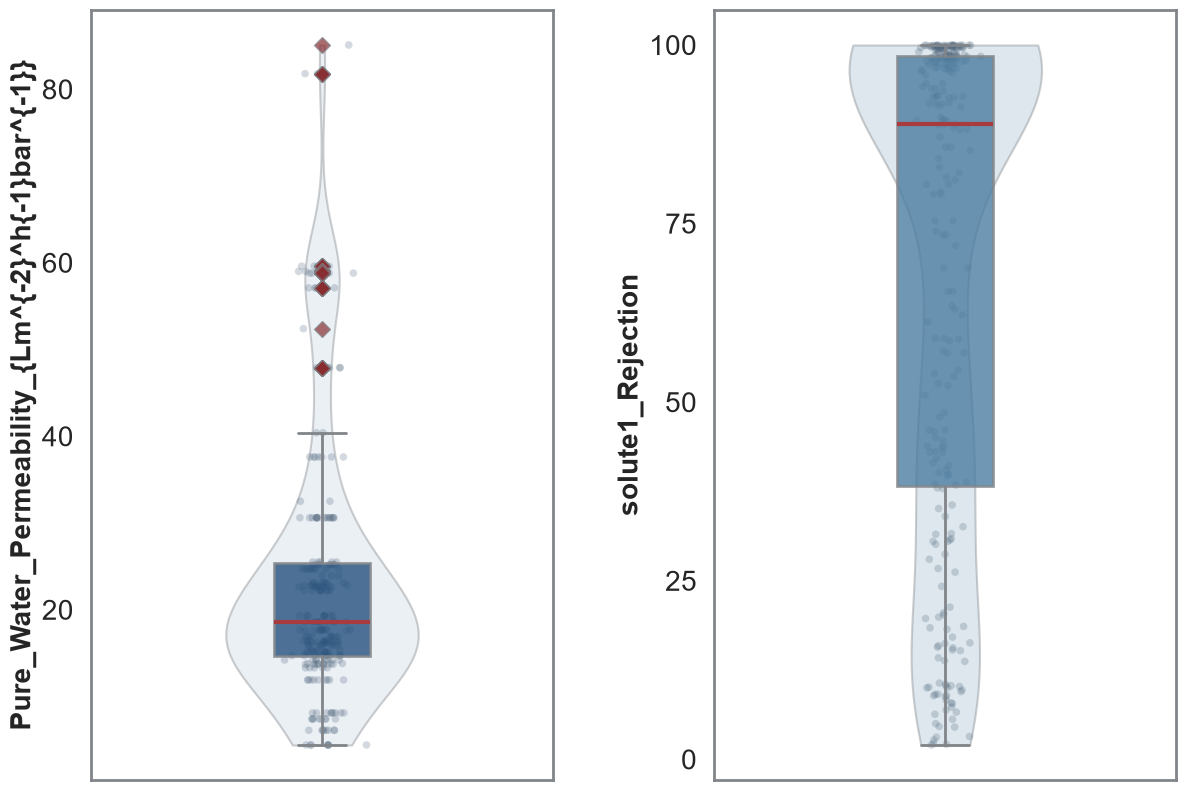

In [8]:
from utl_eda import *
from utl_fileIO import file_io

fig, axes = plot_target_distributions(
    df_enriched_filtered,
    targets,
    fig_size=FIG_SIZE,
)

file_io("save", "figure", FIGURES_DIR, "target_distributions.png", data=fig)
print(f"??Saved target distributions to {FIGURES_DIR}")

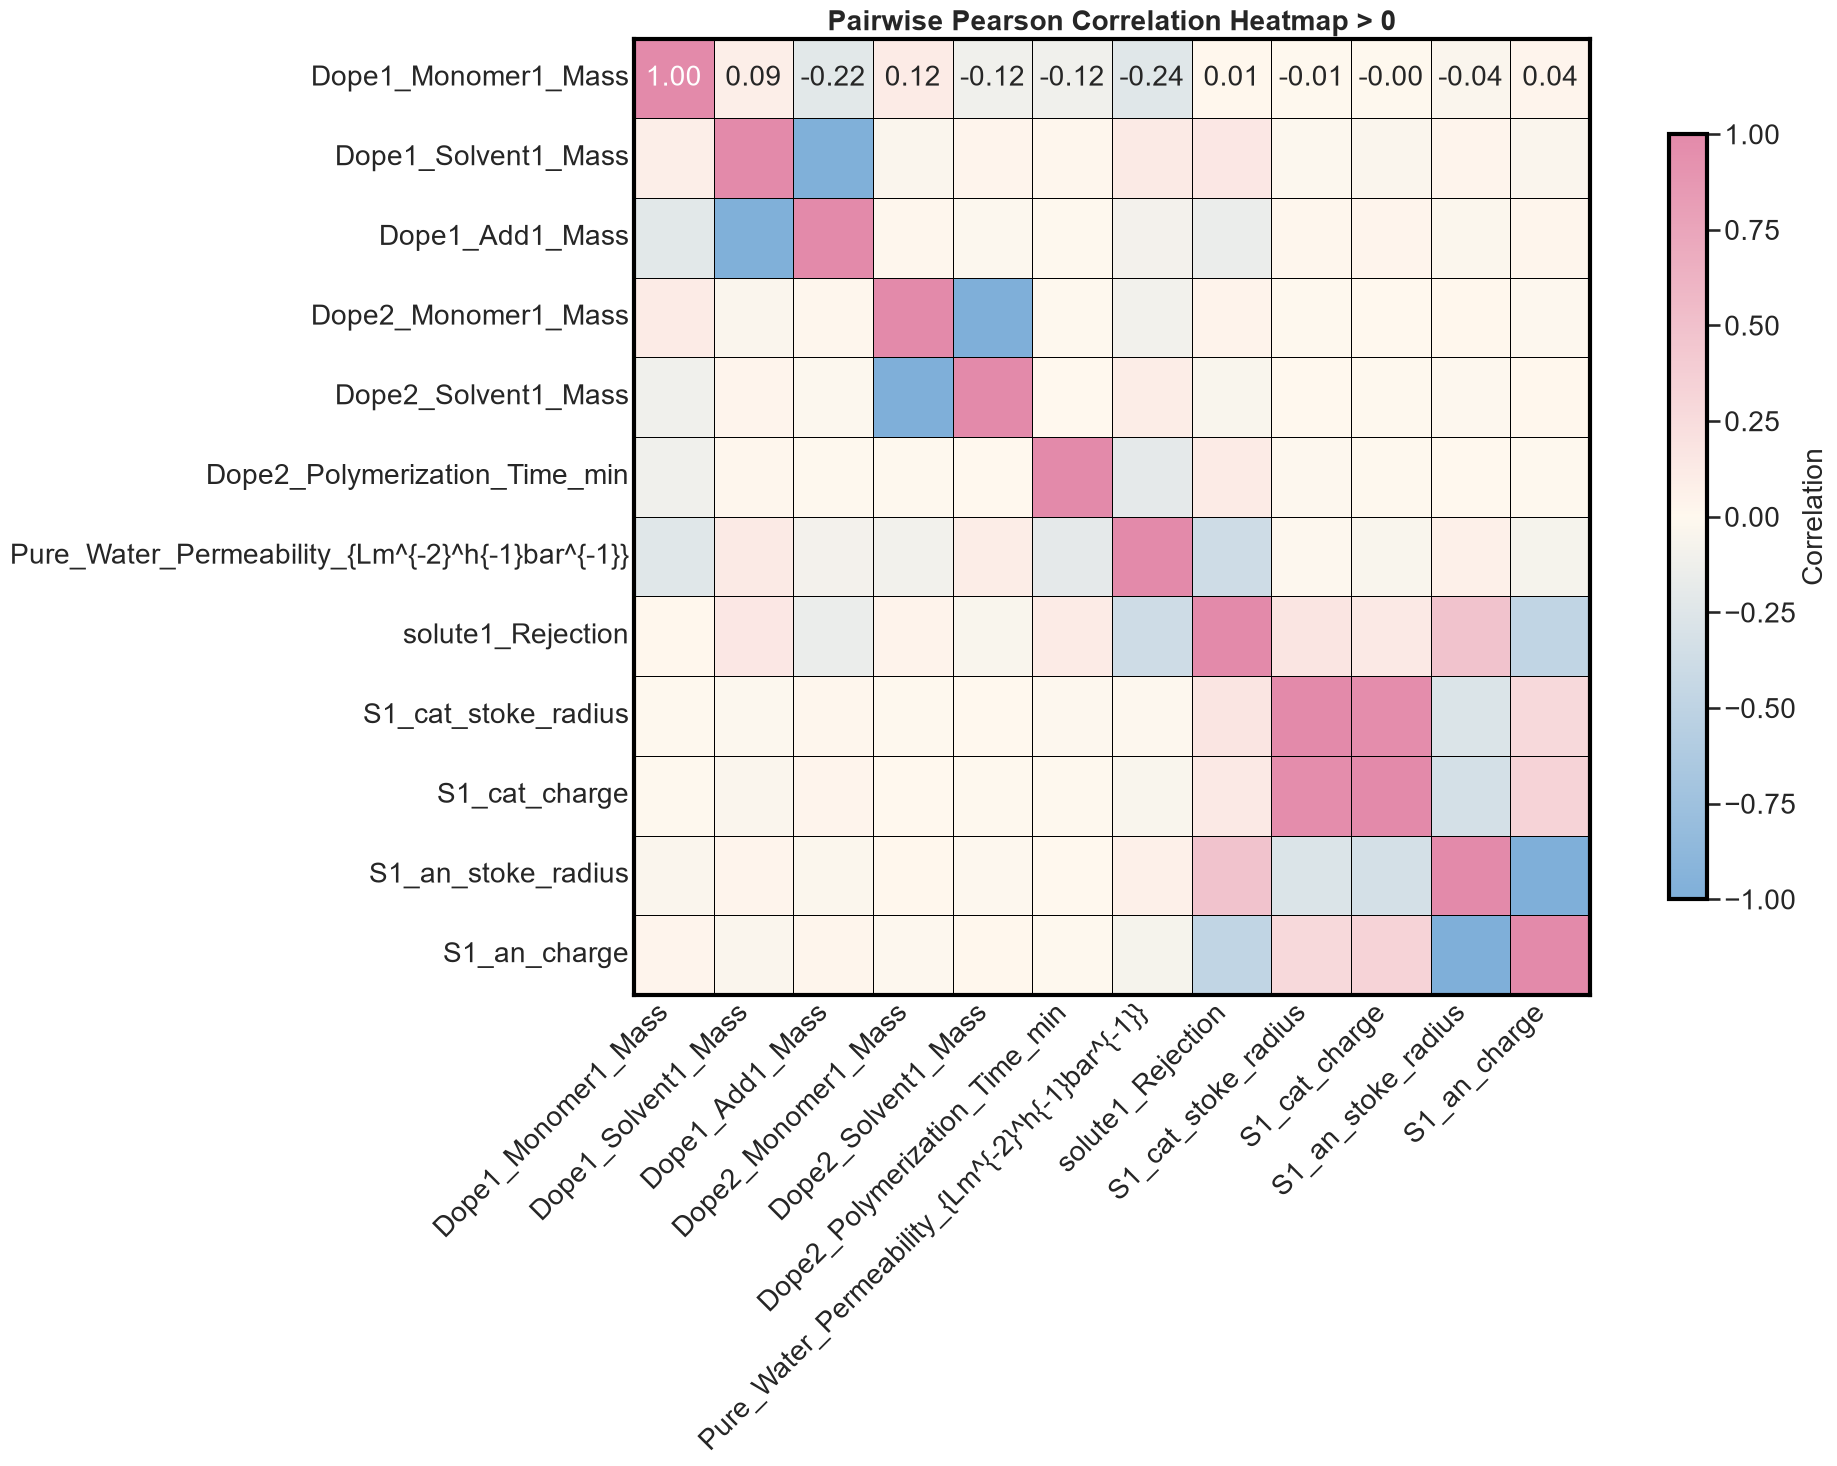

c:\Users\Kai Qi Yan\anaconda3\envs\MLEnv_Brine\Lib\site-packages\seaborn\matrix.py:260: FutureWarning:

Format strings passed to MaskedConstant are ignored, but in future may error or produce different behavior



<Figure size 1400x1000 with 0 Axes>

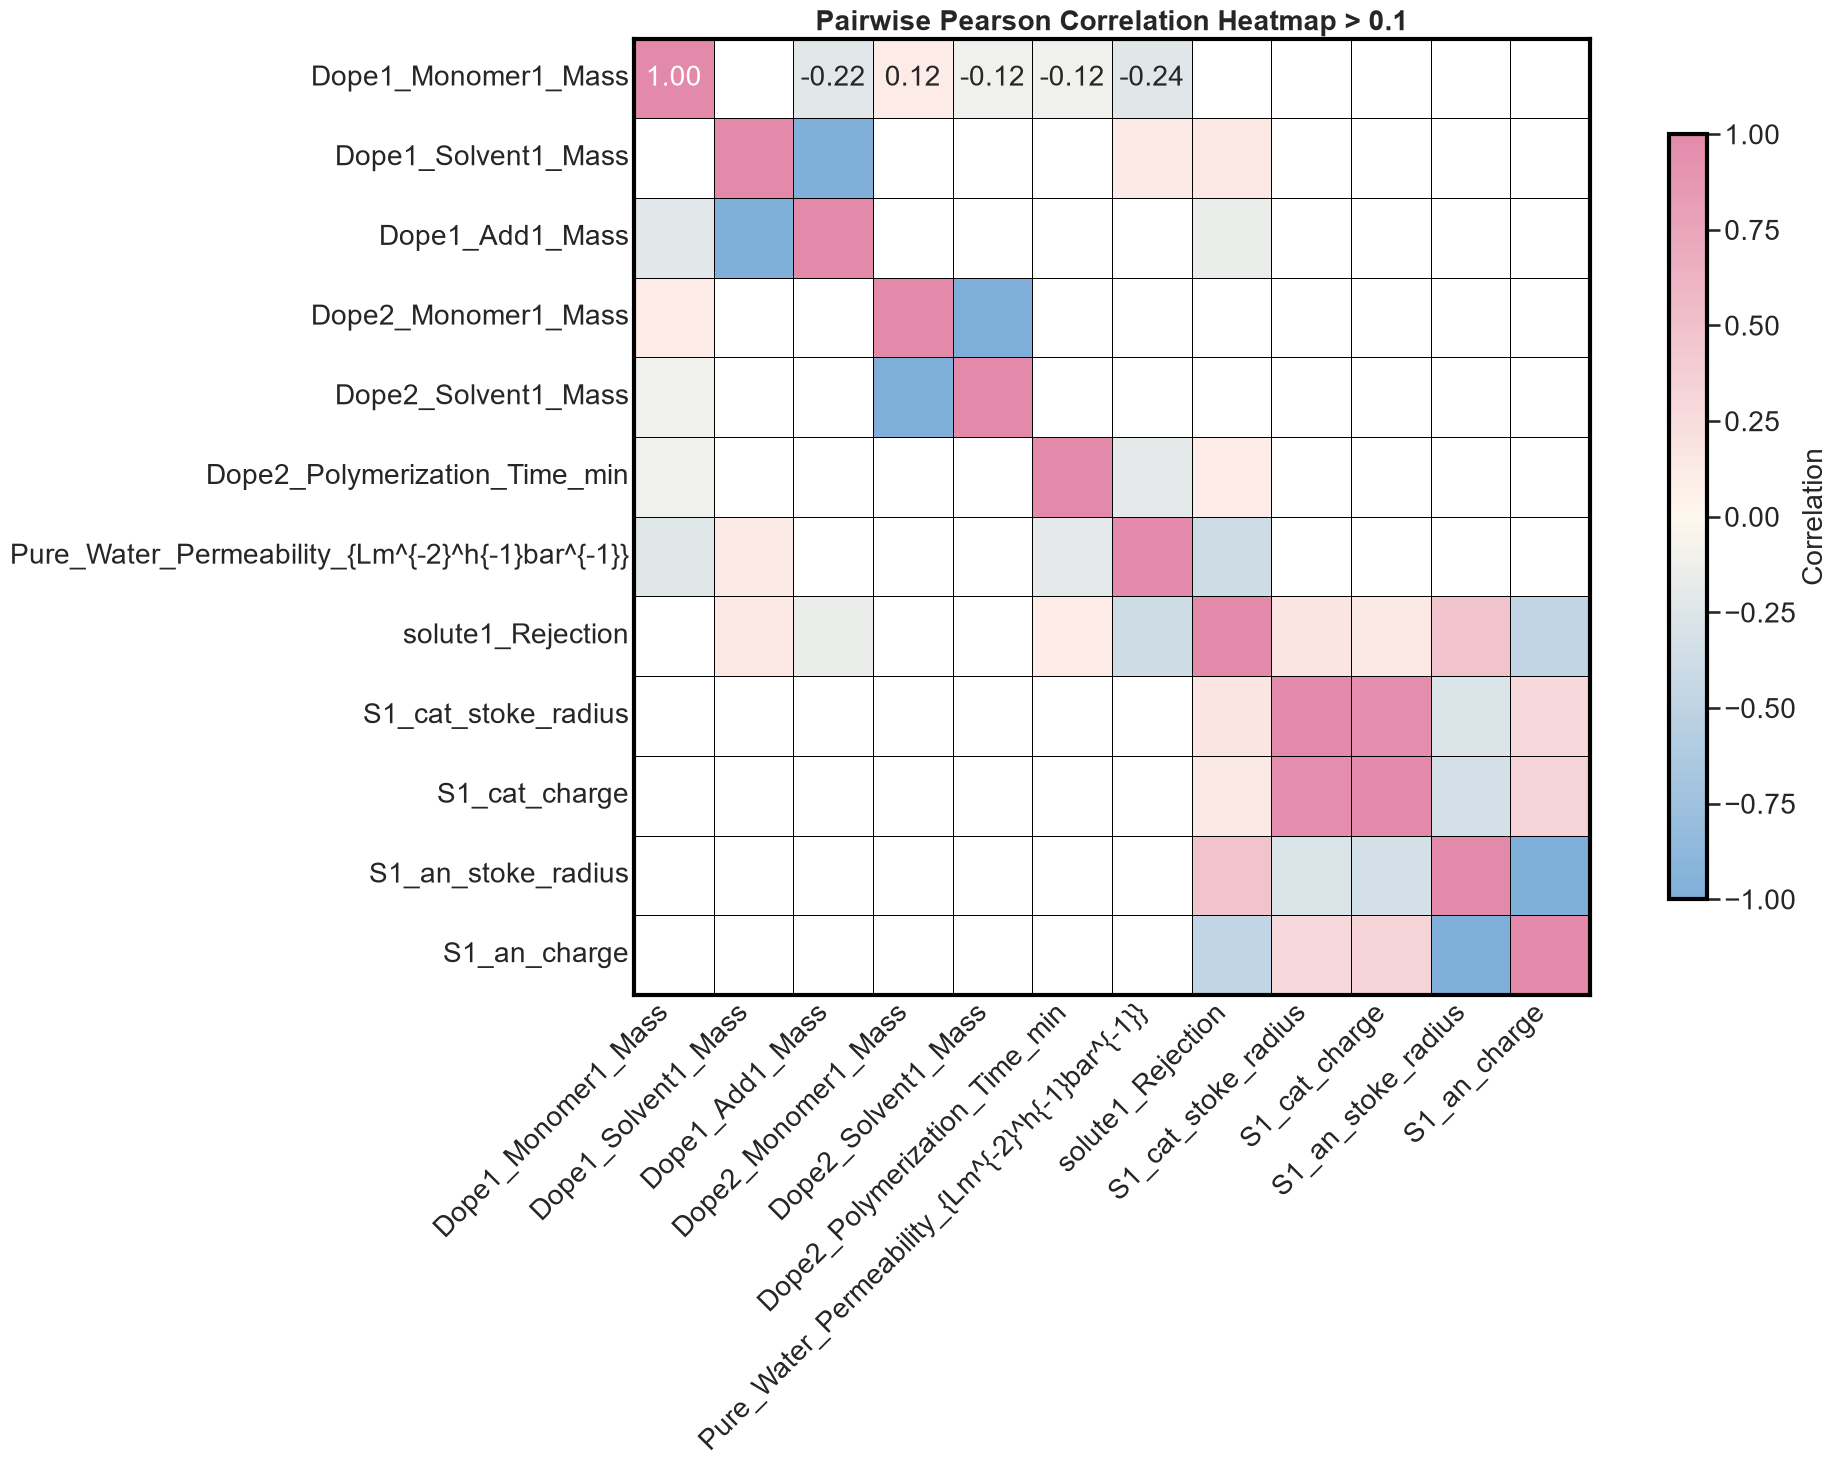

??Generated heatmaps with thresholds: [0, 0.1]


<Figure size 1400x1000 with 0 Axes>

In [9]:
# Compute and plot the Pearson correlation heatmap for the numeric features in the enriched dataframe, using different thresholds to focus on stronger correlations.

from utl_fileIO import file_io

df_enriched_numeric = df_enriched_filtered.select_dtypes(include=[np.number]) # Select only numeric columns for correlation analysis

# Use thresholds from config
correlation_thresholds = config["data_analysis"]["correlation_thresholds"]

for threshold in correlation_thresholds:
    corr_matrix = compute_and_plot_pearson_heatmap(df_enriched_numeric, threshold=threshold, fig_size=[1.5 * x for x in FIG_SIZE])
    heatmap_fig = plt.gcf()
    file_io("save", "figure", FIGURES_DIR, f"pearson_heatmap_threshold_{threshold}.png", data=heatmap_fig)

print(f"??Generated heatmaps with thresholds: {correlation_thresholds}")

### Interpreting the correlation structure

The correlation matrix summarizes how strongly each pair of numeric variables co-varies across the dataset. For membrane development, this structure carries both statistical and physical information.

From a statistical perspective:
- Strong positive or negative correlations between features indicate redundancy and potential multicollinearity. Highly correlated fabrication variables often encode similar underlying variation and may not all be needed in the model.
- Correlations between features and targets provide a first indication of which descriptors are promising predictors, although they do not capture nonlinear or interaction effects that tree-based models can learn.
- Blocks of correlated variables can point to latent “axes” in the data (for example, groups of conditions that are always adjusted together in experiments), which can influence how the model partitions the feature space.

From a physical perspective:
- Correlations between fabrication parameters (such as monomer mass, additive loading, and polymerization time) may reflect experimental design strategies used in the original studies, for example increasing monomer concentration together with reaction time.
- Correlations between ionic descriptors (such as Stokes radius and charge) and performance metrics (permeability and rejection) hint at how size and valence affect transport through the active layer.
- Apparent lack of correlation between certain descriptors and targets can be informative as well, suggesting either weak physical influence under the studied conditions or insufficient variation in the dataset.

These patterns are not definitive mechanistic explanations, but they provide useful hypotheses and guide model-building choices. In later sections, tree-based variable importance and SHAP analysis will complement this linear view by revealing nonlinear and interaction effects that are not visible in the simple correlation matrix.

In [10]:
base_features = [
       'Dope1_Monomer1_Name', 
       'Dope1_Monomer1_Mass',
       'Dope1_Solvent1_Mass', 
       'Dope1_Add1_Name', 
       'Dope1_Add1_Mass',
       'Dope2_Monomer1_Mass', 
       'Dope2_Solvent1_Name', 
       'Dope2_Solvent1_Mass',
       'Dope2_Polymerization_Time_min', 
       'Solute1_Name', 
       'S1_Cation',
       'S1_cat_stoke_radius', 
       'S1_cat_charge',
       'S1_an_stoke_radius', 
       'S1_an_charge'
]

## Section 4. Model Training and Evaluation

With the feature matrix \(X\) and target variable(s) \(y\) defined, we now train supervised regression models to predict membrane performance from fabrication and solute descriptors. In this tutorial, we focus on tree-based ensemble methods, specifically the ExtraTrees regressor implemented in `scikit-learn`.

There are several reasons why tree-based models are a good starting point for this membrane dataset:
- They handle mixed feature types (numeric and one-hot encoded categorical variables) without requiring strong distributional assumptions.
- They can capture nonlinear relationships and interaction effects between fabrication parameters and ionic descriptors, which are common in membrane transport phenomena.
- They provide natural measures of feature importance, which helps connect model predictions back to physically meaningful variables.

The modeling workflow in this section proceeds as follows:
- Construct a `scikit-learn` pipeline that combines preprocessing (encoding of categorical features and passing through numeric features) with an `ExtraTreesRegressor`.
- Split the data into training and test sets using a fixed random seed for reproducibility.
- Fit a baseline model on the training set and evaluate performance on the held-out test set using metrics such as \(R^2\), RMSE, and MAE.
- Optionally perform hyperparameter search (for example, via `RandomizedSearchCV`) to tune the ensemble parameters and compare tuned performance to the baseline.

The emphasis here is on a transparent, reproducible setup rather than exhaustive optimization. The fitted model from this section will also be reused in the interpretation step, where SHAP values are used to analyze how individual features and feature combinations influence permeability and rejection predictions.


=== Modeling target: Pure_Water_Permeability_{Lm^{-2}^h{-1}bar^{-1}} ===
Initial feature count: 15
Initial sample count: 275
Final feature count: 15

=== Training ExtraTrees model for target: Pure_Water_Permeability_{Lm^{-2}^h{-1}bar^{-1}} ===
Training samples: 220 using features: ['Dope1_Monomer1_Name', 'Dope1_Monomer1_Mass', 'Dope1_Solvent1_Mass', 'Dope1_Add1_Name', 'Dope1_Add1_Mass', 'Dope2_Monomer1_Mass', 'Dope2_Solvent1_Name', 'Dope2_Solvent1_Mass', 'Dope2_Polymerization_Time_min', 'Solute1_Name', 'S1_Cation', 'S1_cat_stoke_radius', 'S1_cat_charge', 'S1_an_stoke_radius', 'S1_an_charge']
Test samples: 55
Categorical features: 5
Numerical features: 10
Hyperparameter tuning: ON
Using K-fold CV with n_splits=5.
Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best CV R²: 0.8155
Best parameters:
  model__n_estimators: 200
  model__min_samples_leaf: 2
  model__max_features: 0.8
  model__max_depth: 20

Final performance on train/test split:
Train R²   = 0.9569
Train RMSE = 

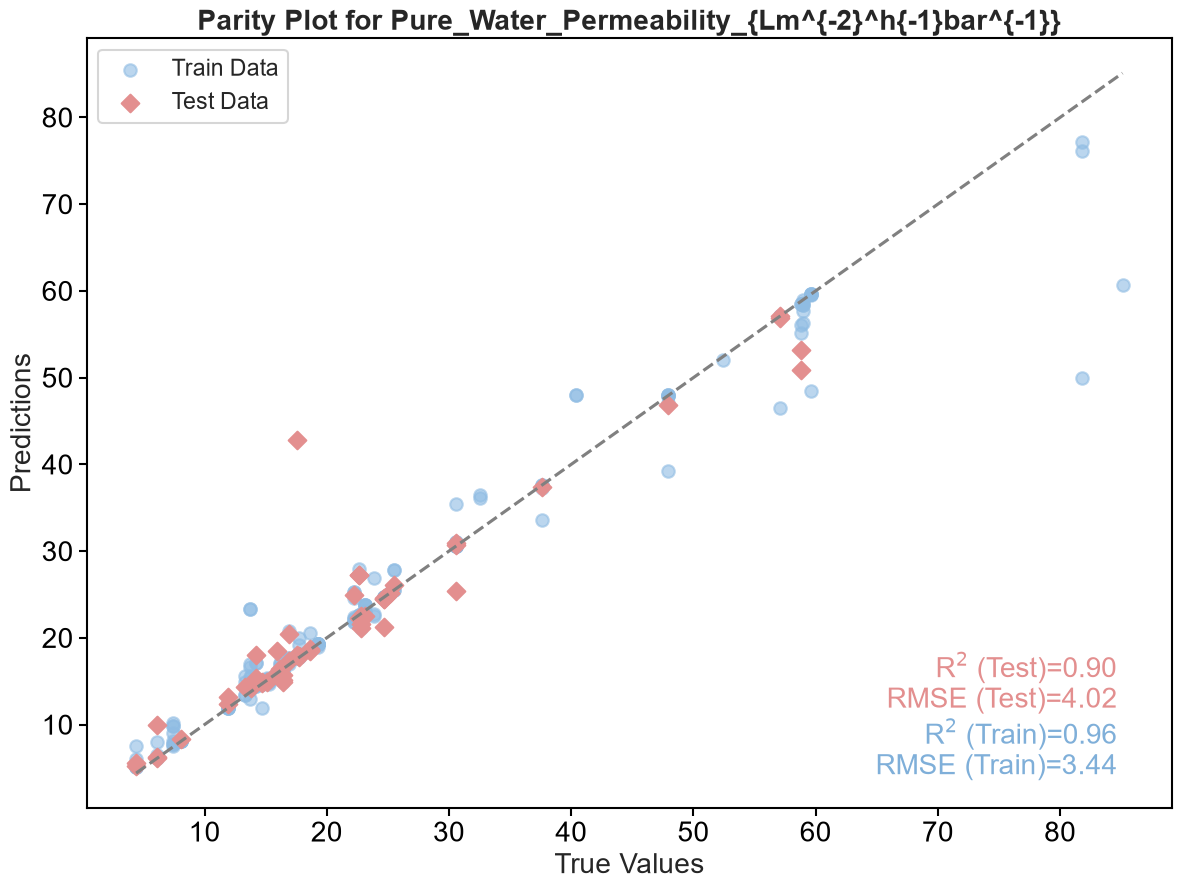


=== Modeling target: solute1_Rejection ===
Initial feature count: 15
Initial sample count: 276
Final feature count: 15

=== Training ExtraTrees model for target: solute1_Rejection ===
Training samples: 220 using features: ['Dope1_Monomer1_Name', 'Dope1_Monomer1_Mass', 'Dope1_Solvent1_Mass', 'Dope1_Add1_Name', 'Dope1_Add1_Mass', 'Dope2_Monomer1_Mass', 'Dope2_Solvent1_Name', 'Dope2_Solvent1_Mass', 'Dope2_Polymerization_Time_min', 'Solute1_Name', 'S1_Cation', 'S1_cat_stoke_radius', 'S1_cat_charge', 'S1_an_stoke_radius', 'S1_an_charge']
Test samples: 56
Categorical features: 5
Numerical features: 10
Hyperparameter tuning: ON
Using K-fold CV with n_splits=5.
Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best CV R²: 0.7260
Best parameters:
  model__n_estimators: 300
  model__min_samples_leaf: 1
  model__max_features: sqrt
  model__max_depth: 40

Final performance on train/test split:
Train R²   = 0.9998
Train RMSE = 0.4912
Train MAE  = 0.0591
Test R²   = 0.8938
Test RMSE = 1

<Figure size 1400x1000 with 0 Axes>

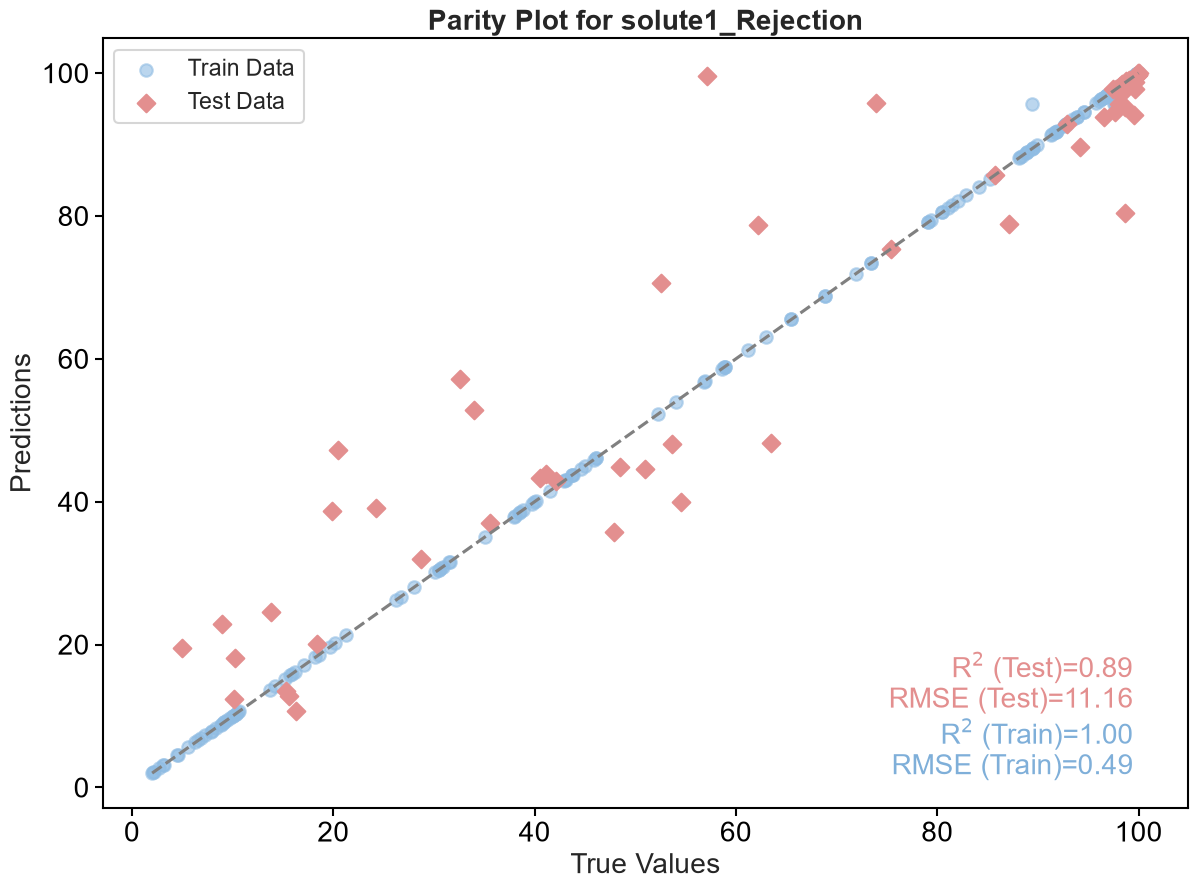

??Completed modeling for 2 targets


<Figure size 1400x1000 with 0 Axes>

In [11]:
from utl_modelling import *
from utl_fileIO import file_io

# Loop over targets
for target in targets:
    print(f"\n=== Modeling target: {target} ===")

    model_path = os.path.join(MODEL_PATH, f"{target}_extratrees.pkl")

    pipe, X_train, X_test, y_train, y_test = train_and_save_extratrees_model(
        df=df_enriched_filtered,              # or df if you don't use enrichment
        base_features=base_features, # your chosen feature list
        target=target,
        model_path=model_path,
        use_kfold=config["modeling"]["use_kfold"],
        use_hyperparam_tuning=config["modeling"]["use_hyperparam_tuning"],
    )

    # Predict on train and test
    y_pred_train = pipe.predict(X_train)
    y_pred_test = pipe.predict(X_test)

    evaluate_and_plot_parity(
        target=target,
        y_train=y_train,
        y_pred_train=y_pred_train,
        y_test=y_test,
        y_pred_test=y_pred_test,
        fig_size=FIG_SIZE,
    )

    safe_target = "".join(ch if ch.isalnum() else "_" for ch in str(target)).strip("_")
    parity_fig = plt.gcf()
    file_io("save", "figure", FIGURES_DIR, f"parity_{safe_target}.png", data=parity_fig)

print(f"??Completed modeling for {len(targets)} targets")

### Evaluating model performance and reading the parity plot

After fitting the ExtraTrees model, performance is quantified using the coefficient of determination (\(R^2\)), the root-mean-squared error (RMSE), and the mean absolute error (MAE) on the held-out test set. Together, these metrics summarize how well the model captures the variability in the target and how large the typical prediction errors are.

From a statistical perspective:
- \(R^2\) indicates the fraction of variance in the target explained by the model; values closer to 1 indicate better fit, while values near 0 suggest that the model is no better than predicting the mean.
- RMSE penalizes large errors more strongly than MAE and is expressed in the same units as the target (for example, permeability or rejection). It is therefore useful for judging whether typical errors are acceptable relative to the dynamic range of the measurements.
- MAE reports the average absolute deviation between predictions and observations, making it less sensitive to rare but very large errors.

The parity plot complements these scalar metrics by showing predicted vs. observed values for each test sample:
- Points lying close to the diagonal line correspond to well-predicted experiments, while systematic deviations from the diagonal indicate bias (for example, consistent underprediction at high permeability).
- The spread of points around the diagonal provides a visual sense of error magnitude and heteroscedasticity, such as whether high-performance membranes are harder to predict than low-performance ones.
- Clusters of points corresponding to specific solutes or fabrication recipes can reveal regimes where the model is particularly strong or weak, hinting at data imbalance or missing descriptors.

In the context of literature-curated membrane datasets with limited sample size, even moderate \(R^2\) values can be informative if the parity plot shows that the model captures the main performance trends without extreme outliers. These results should be interpreted as a data-driven guide to structure–process–performance relationships rather than as a final predictive tool for all possible membranes.

## Section 5. Model Interpretation with SHAP

Once a reasonably performing model has been obtained, the next step is to understand *how* it uses the input features to make predictions. In this section, we use SHAP (SHapley Additive exPlanations) to interpret the ExtraTrees model at both the global and local levels.

SHAP values assign an additive contribution of each feature to each individual prediction, relative to a chosen reference. This has several advantages for membrane modeling:
- It provides a unified way to quantify feature importance that is consistent across different model classes.
- It captures both main effects and interaction effects, which are important in systems where fabrication parameters and ionic descriptors jointly control transport.
- It enables local explanations for specific membranes, not just global rankings of which features matter on average.

The analysis in this section focuses on:
- **Global importance:** SHAP summary plots showing which fabrication variables and ion descriptors most strongly influence permeability and rejection across the dataset.
- **Directional effects:** For key features (e.g., monomer mass, additive loading, Stokes radii), SHAP dependence plots reveal whether increasing a feature tends to increase or decrease the predicted performance, and whether that effect depends on other variables.
- **Local explanations:** Example force plots or decision plots for individual membranes illustrate how the model combines feature contributions to arrive at a particular prediction.

By comparing these SHAP-based insights with physical intuition, we can assess whether the model relies on physically meaningful patterns (for example, higher cation size leading to higher rejection) or on correlations that may be artefacts of the dataset. This fusion of data-driven and physics-based reasoning is central to using machine learning as a tool for membrane design rather than as a black box.

In [12]:
from utl_shap import*


=== SHAP interpretation for target: Pure_Water_Permeability_{Lm^{-2}^h{-1}bar^{-1}} ===
Loaded model from: c:\GITHUB_NEW\ML-MEM-Review\models\Pure_Water_Permeability_{Lm^{-2}^h{-1}bar^{-1}}_extratrees.pkl
Initial feature count: 15
Initial sample count: 275
Final feature count: 15


c:\GITHUB_NEW\ML-MEM-Review\src\utl_shap.py:117: FutureWarning:

The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.



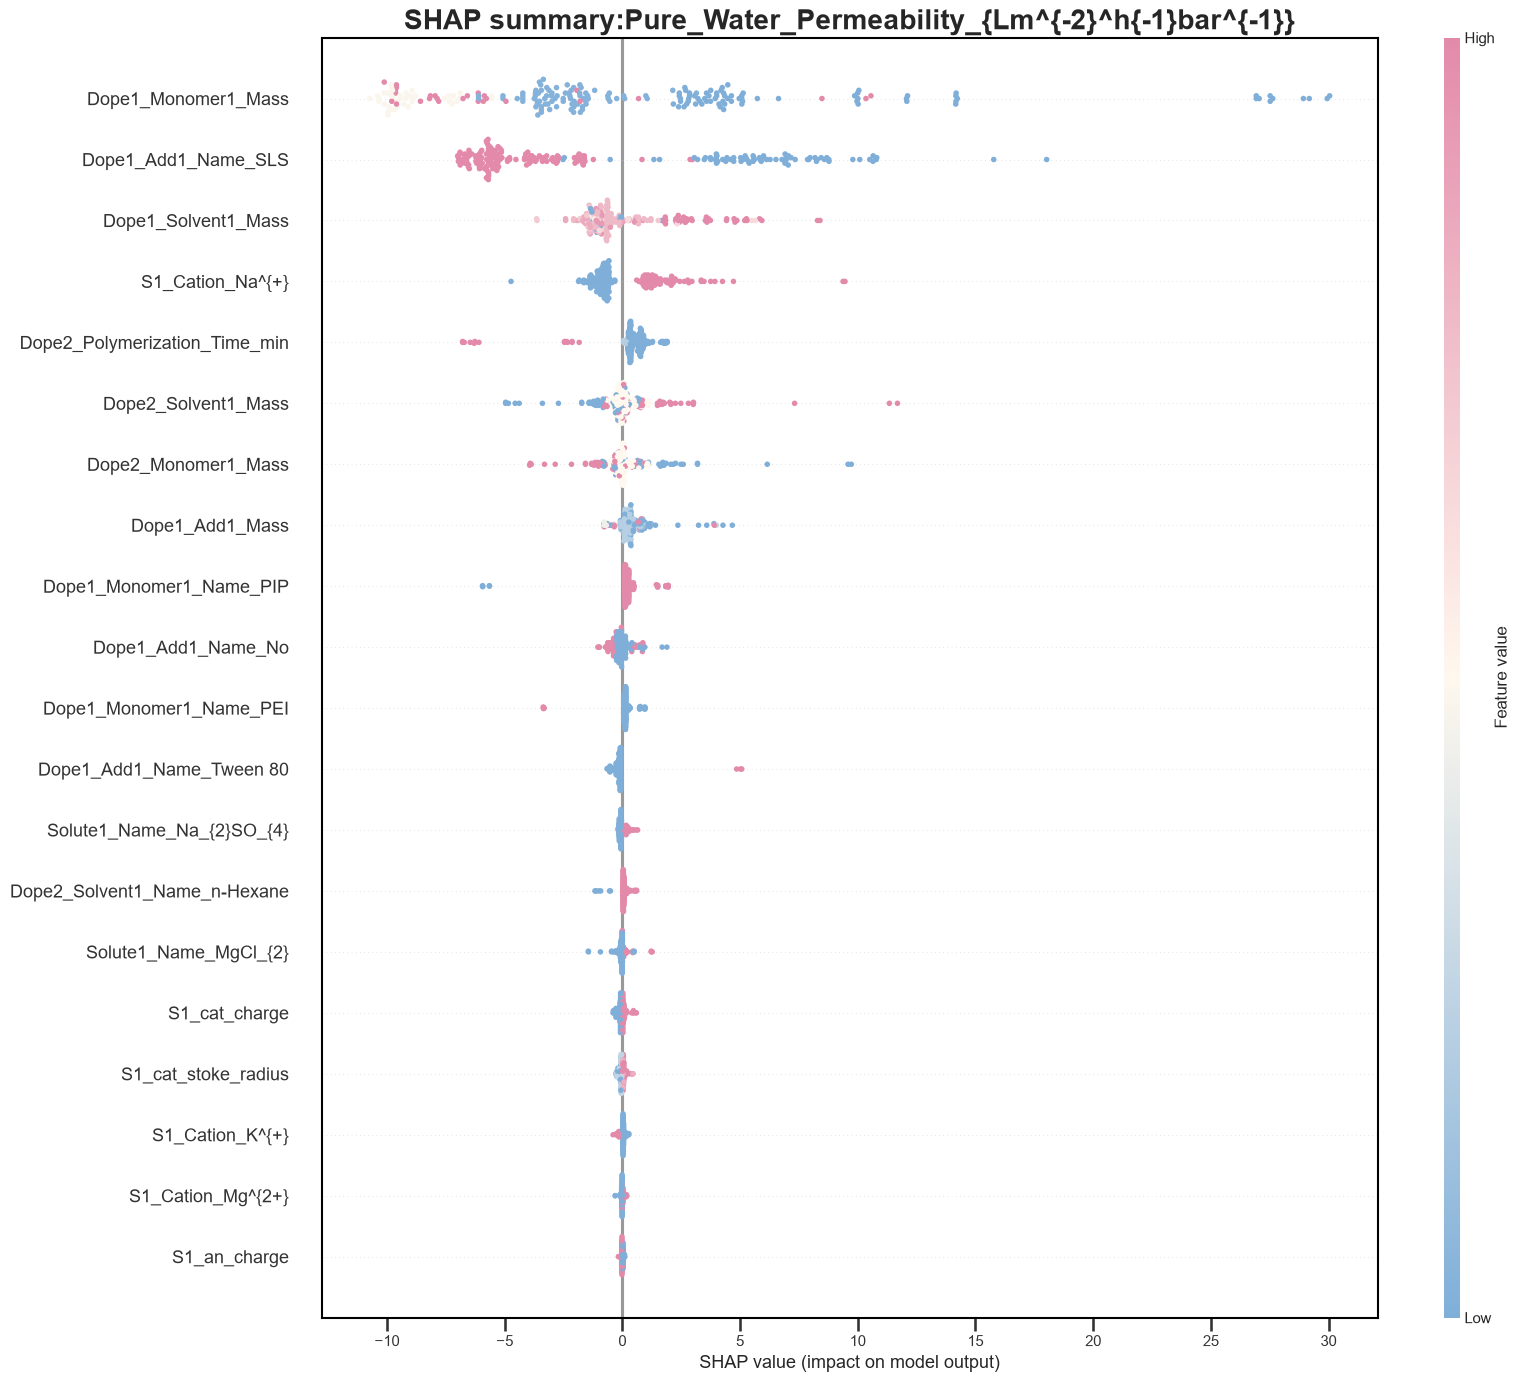

c:\GITHUB_NEW\ML-MEM-Review\src\utl_shap.py:139: FutureWarning:

The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.



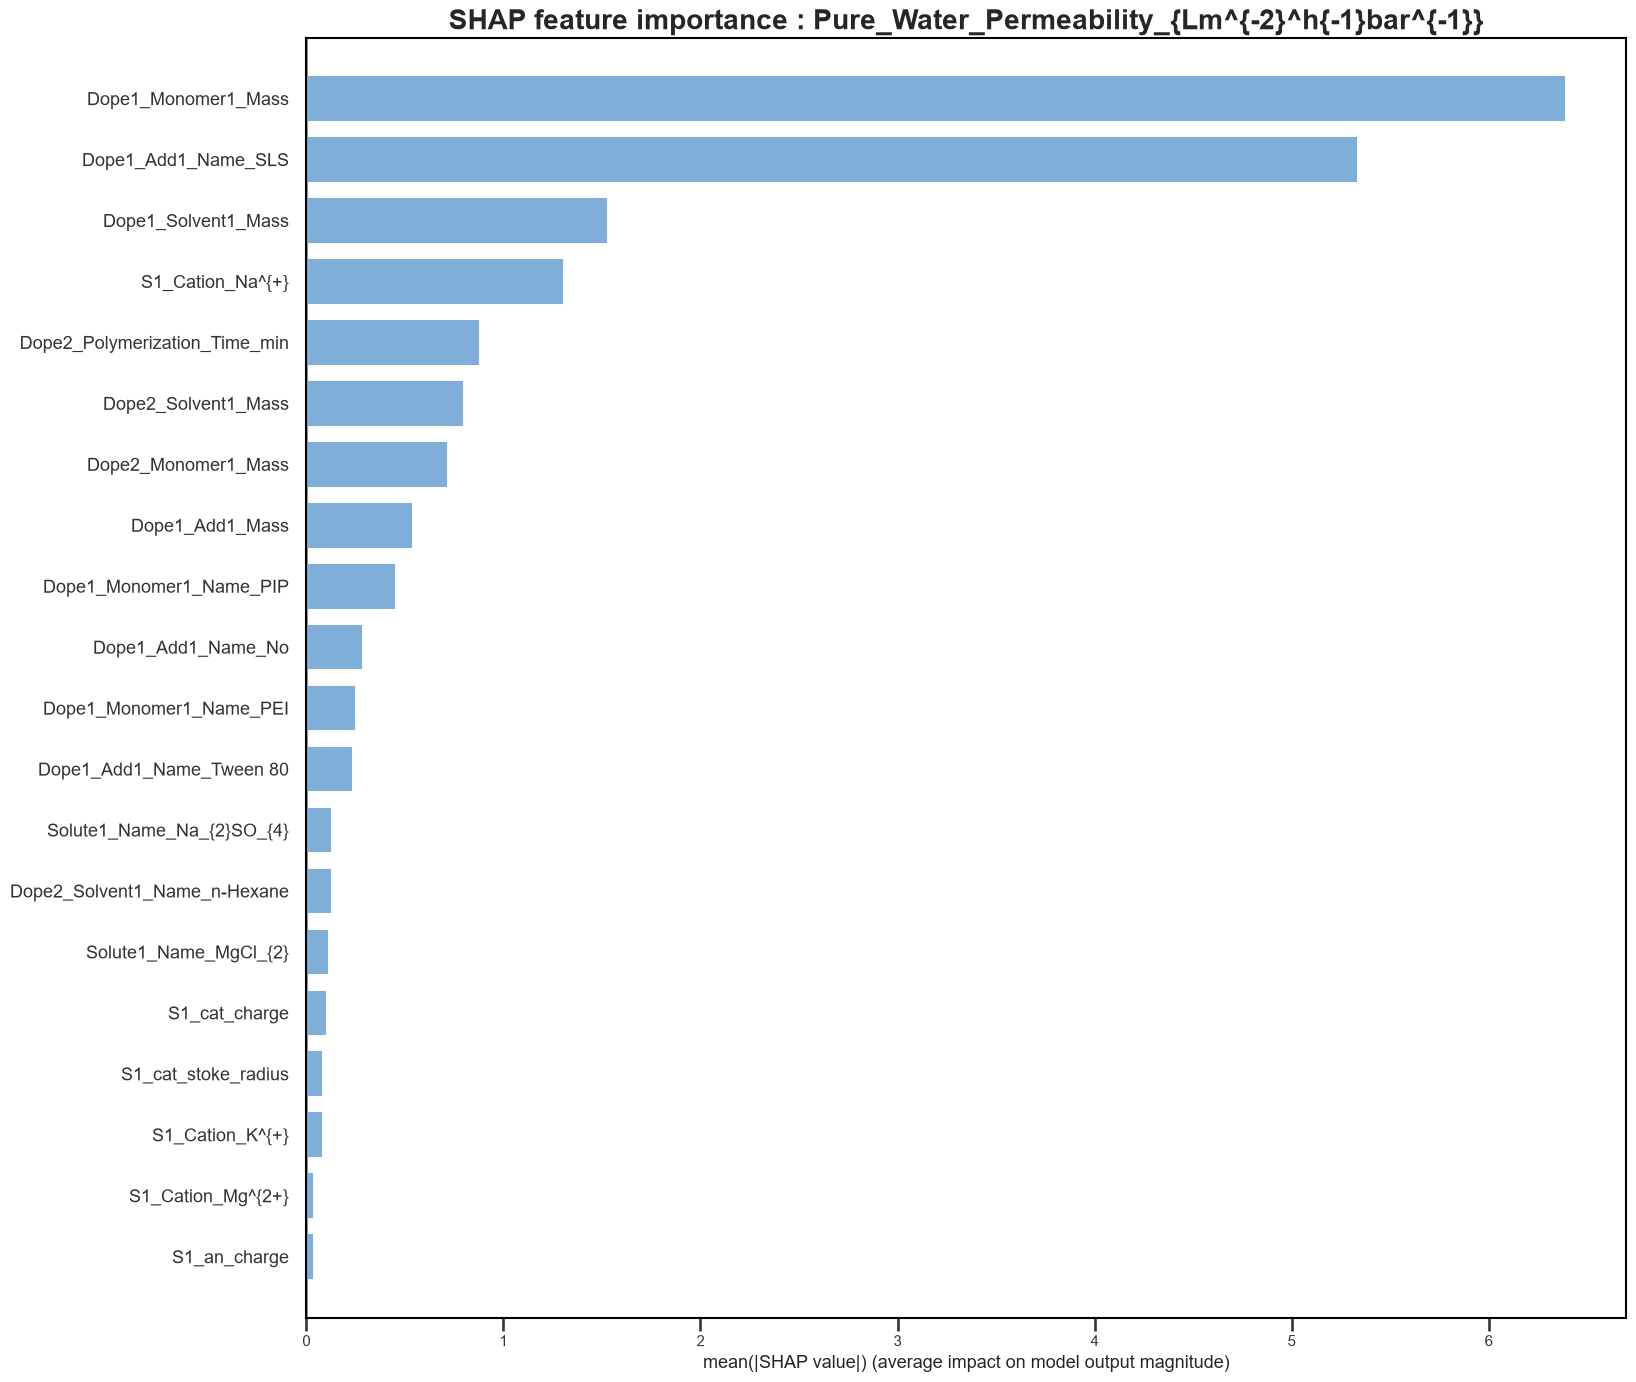


=== SHAP interpretation for target: solute1_Rejection ===
Loaded model from: c:\GITHUB_NEW\ML-MEM-Review\models\solute1_Rejection_extratrees.pkl
Initial feature count: 15
Initial sample count: 276
Final feature count: 15


c:\GITHUB_NEW\ML-MEM-Review\src\utl_shap.py:117: FutureWarning:

The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.



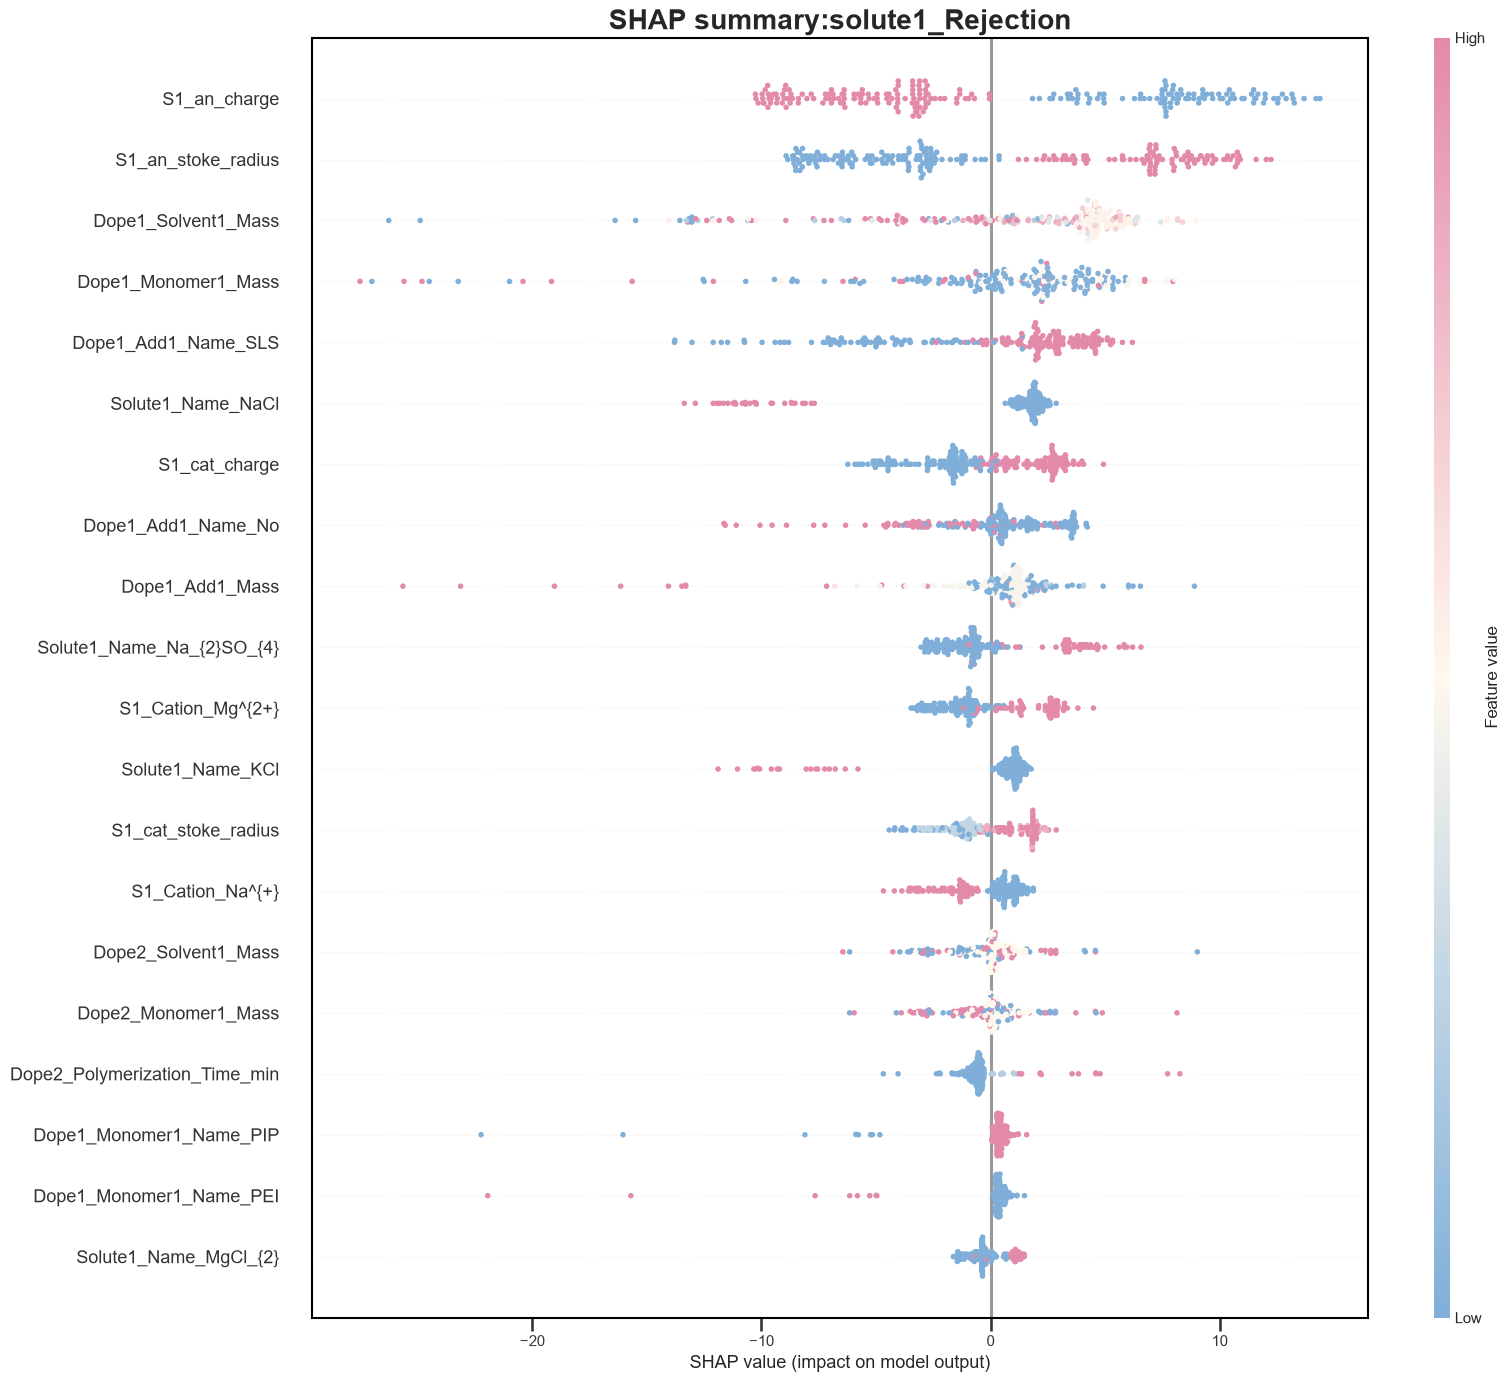

c:\GITHUB_NEW\ML-MEM-Review\src\utl_shap.py:139: FutureWarning:

The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.



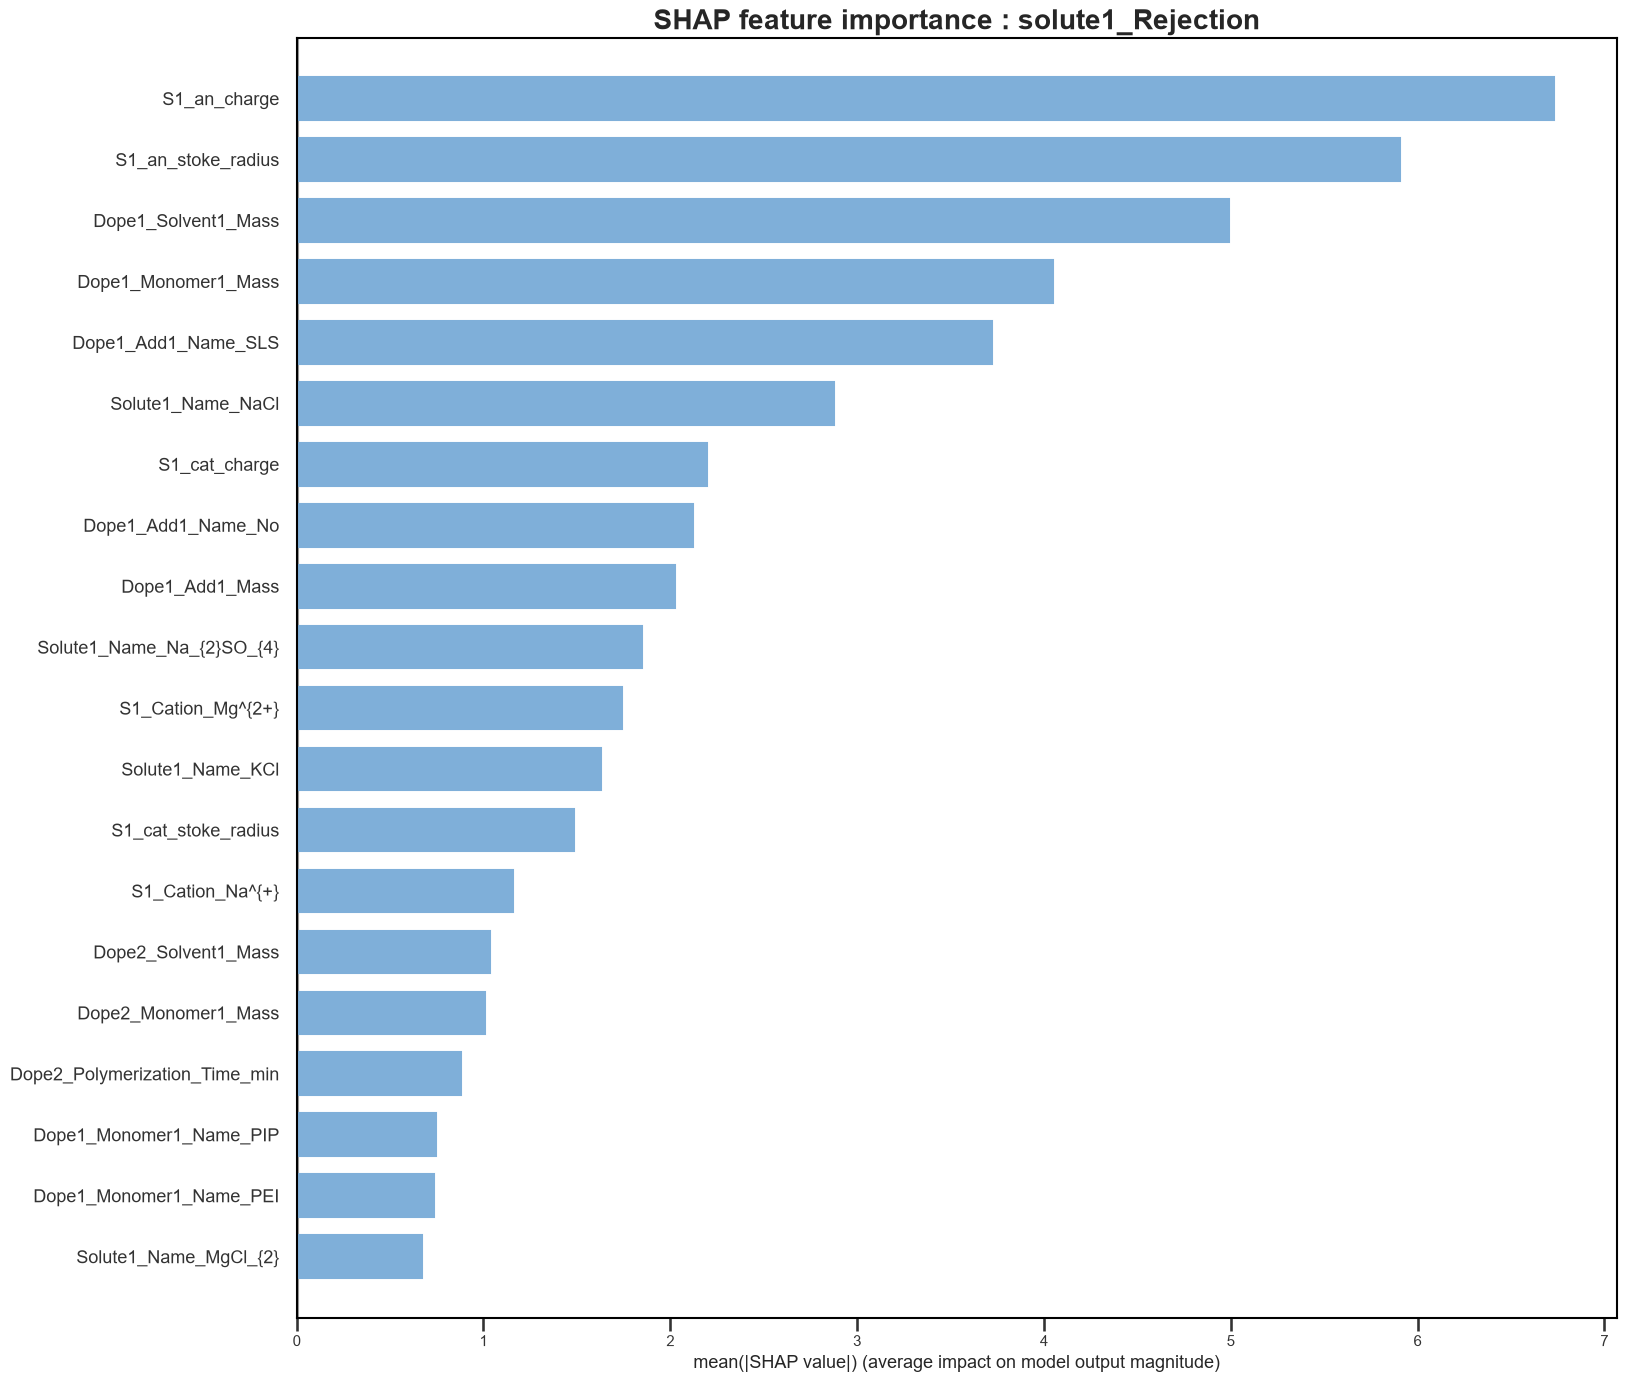

??Completed SHAP analysis for 2 targets


In [ ]:
import importlib
import utl_shap
from utl_fileIO import file_io

utl_shap = importlib.reload(utl_shap)

# Loop over targets to compute and plot SHAP values for model interpretation
for target in targets:
    shap_values, feature_names, summary_fig, bar_fig = utl_shap.shap_explain_target(
        target=target,
        df_enriched=df_enriched,
        base_features=base_features,
        MODEL_PATH=MODEL_PATH,
        random_state=RANDOM_STATE,
        max_samples=1000,
        fig_size=FIG_SIZE,
    )

    safe_target = "".join(ch if ch.isalnum() else "_" for ch in str(target)).strip("_")
    file_io("save", "figure", FIGURES_DIR, f"shap_summary_{safe_target}.png", data=summary_fig)
    file_io("save", "figure", FIGURES_DIR, f"shap_importance_{safe_target}.png", data=bar_fig)

print(f"Completed SHAP analysis for {len(targets)} targets")

### Reading SHAP summary and dependence plots

The SHAP summary plot ranks features by their overall impact on the model predictions and shows, for each feature, how variation across the dataset influences the target:
- Each point corresponds to one membrane sample; its horizontal position is the SHAP value (positive: pushes the prediction up, negative: pushes it down).
- The color encodes the feature value (typically blue = low, red = high), so the joint pattern of position and color indicates whether higher feature values are associated with higher or lower predictions.
- Features are ordered from top to bottom by the sum of the absolute SHAP values, so the top rows correspond to the most influential descriptors for permeability or rejection.

SHAP dependence plots zoom in on a single feature and show how its value relates to its SHAP contribution:
- The horizontal axis is the feature value (for example, monomer mass or cation Stokes radius), and the vertical axis is the SHAP value for the chosen target.
- For permeability, an upward trend in the dependence plot means that increasing that feature tends to increase predicted flux; a downward trend means it tends to decrease flux.
- For rejection, positive SHAP values indicate that the feature configuration pushes the model toward higher predicted rejection, while negative values push toward lower rejection.

By comparing dependence plots for permeability and rejection, we can see whether a given descriptor drives both targets in the same direction (cooperative behavior) or in opposite directions (reflecting trade-offs in selectivity versus permeability). These patterns help connect the model’s behavior back to familiar membrane design trade-offs.

## Section 6. Inverse Design with Ax

In the final section, we use the trained model as a surrogate to explore new membrane formulations via inverse design. Instead of predicting performance for existing experiments, the goal is to search over a space of fabrication variables to find combinations that are likely to yield high permeability and high rejection.

To do this, we couple the model to Ax, a Bayesian optimization library. The workflow is:

- **Define the design space:** Choose a subset of controllable fabrication variables (for example, monomer mass, additive mass and identity, and polymerization time) and specify their allowed ranges or discrete choices. These variables form the search parameters for Ax.
- **Normalize the objectives:** Convert the model-predicted permeability and rejection into normalized scores between 0 and 1 so that they can be combined into a multi-objective or scalarized objective.
- **Set up the optimization problem:** Provide Ax with a function that maps a candidate set of fabrication parameters to the corresponding model predictions and objective value (for example, a weighted sum of normalized permeability and rejection).
- **Run the optimization loop:** Let Ax propose batches of candidate formulations, evaluate them using the surrogate model, and iteratively refine proposals based on the collected data.

The output of this section is a set of candidate membranes with predicted performance near the Pareto front of permeability–rejection trade-offs. These suggestions are not guaranteed to be optimal in the real world, but they illustrate how surrogate-based optimization can be used to prioritize experiments and explore the design space more efficiently than manual tuning.

### Search space and fixed context

Inverse design requires a clear distinction between variables that are allowed to change and variables that are held fixed. In this workflow, the search space contains a focused subset of controllable interfacial polymerization descriptors, while all remaining recipe and testing conditions are supplied through a fixed parameter dictionary so that the optimization problem remains chemically meaningful.

This is a critical design choice. A search space that is too broad becomes unrealistic and difficult to interpret, whereas a focused space allows the optimizer to explore actionable experimental degrees of freedom while preserving a well-defined membrane context. Since the major goal of the inverse design is to enable the experimental validation of the membrane performance of the generated recipes and fabrication conditions, it is important to list ONLY the variables that are actionable in the lab and have a significant impact on the target properties, as identified by SHAP analysis and domain knowledge. 

It is important to note that, the search parameter space, i.e. Ax searchable + fixed parameters must be the same with the parameters space that is used to train the models.

In [14]:
from utl_Ax import*

In [ ]:
# Define a compact search space of IP variables and conditions using config values.
# Tutorial guidance: start narrow (chemically plausible bounds), then expand after validation.

opt_cfg = config["optimization"]

# Build search space parameters from config
search_space_parameters = []

for param_cfg in opt_cfg["search_space"]:
    if param_cfg["type"] == "choice":
        search_space_parameters.append(
            ChoiceParameterConfig(
                name=param_cfg["name"],
                parameter_type="str",
                values=param_cfg["values"],
                is_ordered=param_cfg.get("is_ordered", False),
            )
        )
    elif param_cfg["type"] == "range":
        search_space_parameters.append(
            RangeParameterConfig(
                name=param_cfg["name"],
                parameter_type="float",
                bounds=tuple(param_cfg["bounds"]),
            )
        )

print(f"Built search space with {len(search_space_parameters)} parameters from config")

# Load fixed context parameters from config
constant_params = opt_cfg["constant_parameters"]
print(f"Constant parameters: {list(constant_params.keys())}")

??Built search space with 6 parameters from config
??Constant parameters: ['Dope2_Solvent1_Name', 'Solute1_Name', 'S1_Cation', 'S1_Anion']


### Surrogate oracle

The function `oraclefromparams` acts as the design oracle for optimization. It merges proposed parameter values with default context variables, reconstructs a one-row formulation table, applies the same feature engineering logic used during model training, and then predicts target properties with the saved ExtraTrees pipelines.

This design keeps the optimization workflow aligned with the supervised model. Because candidate formulations pass through the same descriptor construction pipeline as the training data, the inverse-design stage remains consistent with the assumptions embedded in the predictive model.

### Multi-objective scalarization

Membrane optimization is rarely single-objective. In the current notebook, the predicted values of `Pure_Water_Permeability_{Lm^{-2}^h{-1}bar^{-1}}` and `solute1_Rejection` are normalized and then combined into a single scalar objective using `normdict`, `weightdict`, and `scalarizedobjective`.

This scalarization reflects a common membrane design trade-off: improving permeability is useful only if rejection remains sufficiently high. The weighting scheme therefore encodes an explicit design preference and makes the optimization problem transparent rather than leaving the trade-off implicit.

In [16]:
# Build normalization and weighting dictionaries from config
opt_cfg = config["optimization"]

norm_dict = {}
weight_dict = {}

for obj_cfg in opt_cfg["objectives"]:
    # Use the original name as the key for norm_dict
    original_name = obj_cfg["original_name"]
    norm_dict[original_name] = (
        obj_cfg["normalization_min"],
        obj_cfg["normalization_max"]
    )
    
    # Use the normalized name as the key for weight_dict
    weight_dict[original_name] = obj_cfg["weight"]

print(f"??Loaded normalization ranges from config:")
for key, (min_val, max_val) in norm_dict.items():
    print(f"  - {key}: [{min_val}, {max_val}]")

print(f"??Loaded objective weights from config:")
for key, weight in weight_dict.items():
    print(f"  - {key}: {weight}")

??Loaded normalization ranges from config:
  - PureWaterPermeability: [4.4, 85.1]
  - solute1Rejection: [2.0, 99.99]
??Loaded objective weights from config:
  - PureWaterPermeability: 0.1
  - solute1Rejection: 0.9


### Bayesian optimization loop

The Ax client iteratively proposes candidate formulations, evaluates them through the surrogate oracle, and updates its belief about where promising regions of the search space may lie. This sequential strategy is well suited to materials design problems because it can balance exploration of uncertain regions with exploitation of high-performing candidates.

In the context of membrane development, the optimizer should be viewed as a screening tool. Its role is to narrow the experimental search space and rank plausible candidates, not to replace fabrication and testing.

In [17]:
OPTIMIZATION_MODE = opt_cfg["mode"]  # Loaded from config

# Build explicit objective thresholds for multiobjective runs from config.
# Accept threshold formats like ">=0.06", "<= 0.8", or full expressions.
OBJECTIVE_THRESHOLDS = []
for obj_cfg in opt_cfg["objectives"]:
    threshold_raw = str(obj_cfg["threshold"]).strip()
    normalized_name = obj_cfg["name"]

    if any(op in threshold_raw for op in [">=", "<=", ">", "<"]):
        # If only the inequality/value is provided, prefix the metric name.
        if normalized_name not in threshold_raw:
            threshold_expr = f"{normalized_name}{threshold_raw}"
        else:
            threshold_expr = threshold_raw
    else:
        # Backward-compatible fallback: treat bare numbers as lower bounds.
        threshold_expr = f"{normalized_name}>={threshold_raw}"

    OBJECTIVE_THRESHOLDS.append(threshold_expr)

print(f"Optimization mode: {OPTIMIZATION_MODE}")
print(f"Objective thresholds: {OBJECTIVE_THRESHOLDS}")

client, results = run_ax_optimization(
    search_space_parameters=search_space_parameters,
    oracle_from_params=oracle_from_params,
    constant_params=constant_params,
    norm_dict=norm_dict,
    weight_dict=weight_dict,
    cation_path=CATION_PROP_PATH,
    anion_path=ANION_PROP_PATH,
    model_path=MODEL_PATH,
    optimization_mode=OPTIMIZATION_MODE,
    objective_thresholds=OBJECTIVE_THRESHOLDS,
    sobol_init=opt_cfg["sobol_init"],
    n_trials=opt_cfg["n_trials"],
    force_rebuild=True,
    save_every_trials=opt_cfg["save_checkpoint_every"],
    client_path=os.path.join(MODEL_PATH, opt_cfg["client_cache_file"]),
    config=config,  # Pass config for path resolution in oracle
)

print(f"Optimization completed: {len(results)} trials")

Optimization mode: multiobjective
Objective thresholds: ['normPureWaterPermeability>=0.06', 'solute1Rejection>=0.75']


[INFO 06-21 17:34:52] ax.api.client: GenerationStrategy(name='Center+Sobol+MBM:fast', nodes=[CenterGenerationNode(next_node_name='Sobol', use_existing_trials_for_initialization=True), GenerationNode(name='Sobol', generator_specs=[GeneratorSpec(generator_enum=Sobol, generator_key_override=None)], transition_criteria=[MinTrials(transition_to='MBM'), MinTrials(transition_to='MBM')], suggested_experiment_status=ExperimentStatus.INITIALIZATION, pausing_criteria=[MaxTrialsAwaitingData(threshold=5)]), GenerationNode(name='MBM', generator_specs=[GeneratorSpec(generator_enum=BoTorch, generator_key_override=None)], transition_criteria=None, suggested_experiment_status=ExperimentStatus.OPTIMIZATION, pausing_criteria=None)]) chosen based on user input and problem structure.
[INFO 06-21 17:34:52] ax.api.client: Generated new trial 0 with parameters {'Dope1_Monomer1_Name': 'PEI', 'Dope1_Monomer1_Mass': 0.01005, 'Dope1_Add1_Name': 'CTAB', 'Dope1_Add1_Mass': 0.144387, 'Dope2_Monomer1_Mass': 0.001, 'Do


Trial 0: parameters = {'Dope1_Monomer1_Name': 'PEI', 'Dope1_Monomer1_Mass': 0.01005, 'Dope1_Add1_Name': 'CTAB', 'Dope1_Add1_Mass': 0.1443865, 'Dope2_Monomer1_Mass': 0.001, 'Dope2_Polymerization_Time_min': 10.0415}


[INFO 06-21 17:34:52] ax.api.client: Trial 0 marked COMPLETED.
[INFO 06-21 17:34:53] ax.api.client: Generated new trial 1 with parameters {'Dope1_Monomer1_Name': 'PEI', 'Dope1_Monomer1_Mass': 0.003601, 'Dope1_Add1_Mass': 0.264782, 'Dope2_Monomer1_Mass': 0.000734, 'Dope2_Polymerization_Time_min': 9.929002, 'Dope1_Add1_Name': 'CTAB'} using GenerationNode Sobol.


  metrics: {'normPureWaterPermeability': (0.3004058240396539, 0.01), 'solute1Rejection': (0.4834132734632777, 0.01)}

Trial 1: parameters = {'Dope1_Monomer1_Name': 'PEI', 'Dope1_Monomer1_Mass': 0.003601303401589394, 'Dope1_Add1_Mass': 0.264782483899653, 'Dope2_Monomer1_Mass': 0.0007343982309103012, 'Dope2_Polymerization_Time_min': 9.929001917511226, 'Dope1_Add1_Name': 'CTAB'}


...

  metrics: {'normPureWaterPermeability': (0.03048977695167286, 0.01), 'solute1Rejection': (0.9669728203558215, 0.01)}


[INFO 06-21 18:00:39] ax.api.client: Generated new trial 99 with parameters {'Dope1_Monomer1_Name': 'PIP', 'Dope1_Monomer1_Mass': 0.015767, 'Dope1_Add1_Mass': 0.081933, 'Dope2_Monomer1_Mass': 0.001492, 'Dope2_Polymerization_Time_min': 16.023071, 'Dope1_Add1_Name': 'SLS'} using GenerationNode MBM.



Trial 99: parameters = {'Dope1_Monomer1_Name': 'PIP', 'Dope1_Monomer1_Mass': 0.015766868002008338, 'Dope1_Add1_Mass': 0.0819330556701353, 'Dope2_Monomer1_Mass': 0.0014917196211720102, 'Dope2_Polymerization_Time_min': 16.023071041266412, 'Dope1_Add1_Name': 'SLS'}


[INFO 06-21 18:00:40] ax.api.client: Trial 99 marked COMPLETED.


  metrics: {'normPureWaterPermeability': (0.03325464684014873, 0.01), 'solute1Rejection': (0.9667585127734147, 0.01)}
Checkpoint saved after 100 completed trials to: c:\GITHUB_NEW\ML-MEM-Review\models\ax_client.pkl
Saved Ax client to: c:\GITHUB_NEW\ML-MEM-Review\models\ax_client.pkl
Optimization completed: 100 trials


### Interpreting the inverse design results

The Ax optimization history shows how the scalar objective (combining normalized permeability and rejection) improves over successive trials. Early iterations typically explore the design space broadly, while later iterations exploit regions where the surrogate predicts high performance.

The final set of top-ranked candidates highlights specific fabrication recipes with favorable trade-offs. By inspecting these candidates, we can:
- identify trends in monomer and additive loading that the model associates with high flux and high rejection,
- compare the recommended polymerization times to those commonly used in the original dataset,
- select a small number of promising formulations for experimental validation.

Because the optimization is carried out on a surrogate trained on limited literature data, the results should be treated as hypotheses rather than definitive prescriptions. Nonetheless, this workflow demonstrates how machine learning and Bayesian optimization can work together to guide membrane development toward high-performance regions of the design space.

In [18]:
# Retrieve and inspect optimization recommendations from Ax.
# Works for both scalarized (single best point) and multiobjective (Pareto frontier).

import warnings
from numbers import Number




recommendations = get_optimization_recommendations(
    client=client,
    optimization_mode=OPTIMIZATION_MODE,
    top_k=5,
)

# Tutorial next step: validate top recommendation(s) experimentally (or with held-out data),
# then append outcomes and rerun BO for closed-loop improvement.


Pareto frontier size: 11
Showing first 5 Pareto points:

Point 1:
  trial_index: 69
  params:
    Dope1_Monomer1_Name: PIP
    Dope1_Monomer1_Mass: 0.0001
    Dope1_Add1_Name: SLS
    Dope1_Add1_Mass: 0.0853034067054411
    Dope2_Monomer1_Mass: 0.0012241751472432706
    Dope2_Polymerization_Time_min: 2.276240641798834
  metrics (mean, sem):
    normPureWaterPermeability: mean=0.4026, sem=0.0001
    solute1Rejection: mean=0.8468, sem=0.0000

Point 2:
  trial_index: 59
  params:
    Dope1_Monomer1_Name: PIP
    Dope1_Monomer1_Mass: 0.0001
    Dope1_Add1_Name: SLS
    Dope1_Add1_Mass: 0.12826128328943837
    Dope2_Monomer1_Mass: 0.0014420678889745223
    Dope2_Polymerization_Time_min: 1.704580487846517
  metrics (mean, sem):
    normPureWaterPermeability: mean=0.4096, sem=0.0001
    solute1Rejection: mean=0.8273, sem=0.0001

Point 3:
  trial_index: 29
  params:
    Dope1_Monomer1_Name: PIP
    Dope1_Monomer1_Mass: 0.006325169871179241
    Dope1_Add1_Name: Tween80
    Dope1_Add1_Mass: 0.0

### Visualizing the inverse design results

The Ax visualizations summarize how the optimization explores and exploits the fabrication design space using the surrogate model.

1. **Objective vs trial index**

The objective-history plot shows the scalar objective value (for example, a weighted sum of normalized permeability and rejection) for each Ax trial:
- Early trials often have a wide spread of objective values, reflecting the initial exploration of the design space.
- As the optimization progresses, Ax proposes candidates that increasingly cluster near the upper part of the objective range, indicating exploitation of regions predicted to perform well.
- A plateau in the best-seen objective suggests that, under the current surrogate and search space, further improvement is limited without new experimental data.

2. **Permeability–rejection scatter of candidates**

A scatter plot of predicted permeability vs rejection for the Ax-generated candidates helps connect the scalar objective back to familiar membrane performance trade-offs:
- Points near the upper-right region correspond to candidates with simultaneously high permeability and high rejection, i.e., near the Pareto front.
- Color-coding by trial index or objective value reveals how the optimization moves from broadly scattered points to a denser cluster in the high-performance region.
- Comparing this scatter to the original dataset highlights whether Ax is mainly refining around known high-performance recipes or suggesting extrapolations beyond the observed regime.

3. **Top candidate table**

The summary table of top-ranked candidates lists the fabrication variables (e.g., monomer and additive masses, additive identity, polymerization time) alongside the model-predicted permeability and rejection:
- Examining patterns in this table can reveal design motifs, such as preferred additive identity or specific ranges of monomer loading.
- Differences between candidates with similar objective values but different recipes can suggest alternative experimental routes to comparable performance.

These visualizations should be interpreted as *hypothesis generators*: they indicate where the surrogate expects high performance and how the optimization navigates the design space, but experimental validation is required to confirm whether the predicted gains are realized in practice.

c:\GITHUB_NEW\ML-MEM-Review\src\utl_Ax.py:972: UserWarning:

The `rotation` parameter has not yet been implemented and is currently ignored.

c:\GITHUB_NEW\ML-MEM-Review\src\utl_Ax.py:986: UserWarning:

The `rotation` parameter has not yet been implemented and is currently ignored.



,normPureWaterPermeability,solute1Rejection,trial_index,objective_sum
0,0.300406,0.483413,0,0.465113
1,0.401827,0.440191,1,0.436355
2,0.231992,0.781818,2,0.726835
3,0.346036,0.823679,3,0.775915
4,0.053459,0.459707,4,0.419082
...,...,...,...,...
95,0.027746,0.961591,95,0.868207
96,0.029536,0.964670,96,0.871157
97,0.063046,0.963806,97,0.873730
98,0.030490,0.966973,98,0.873325


,Dope1_Monomer1_Name,Dope1_Monomer1_Mass,Dope1_Add1_Name,Dope1_Add1_Mass,Dope2_Monomer1_Mass,Dope2_Polymerization_Time_min,normPureWaterPermeability,solute1Rejection
0,PIP,0.000100,SLS,0.085303,0.001224,2.276241,0.411950,0.834316
1,PIP,0.010216,Tween80,0.085637,0.000848,20.000000,0.311025,0.847797
2,PIP,0.006325,Tween80,0.094032,0.000842,20.000000,0.418469,0.817335
3,PIP,0.000100,SLS,0.128261,0.001442,1.704580,0.418902,0.816808
4,PIP,0.010033,Tween80,0.084875,0.000832,20.000000,0.312890,0.843205
5,PIP,0.011006,Tween80,0.088334,0.000787,20.000000,0.313448,0.838718
6,PIP,0.004840,Tween80,0.093910,0.000861,20.000000,0.454368,0.800429
7,PIP,0.000100,SLS,0.118192,0.001207,16.447048,0.223744,0.866946
8,PIP,0.003050,Tween80,0.095551,0.000868,20.000000,0.488776,0.791462
9,PIP,0.000549,SLS,0.080873,0.001500,0.083000,0.143783,0.930340



??All inverse design visualizations saved to c:\GITHUB_NEW\ML-MEM-Review\outputs/figures


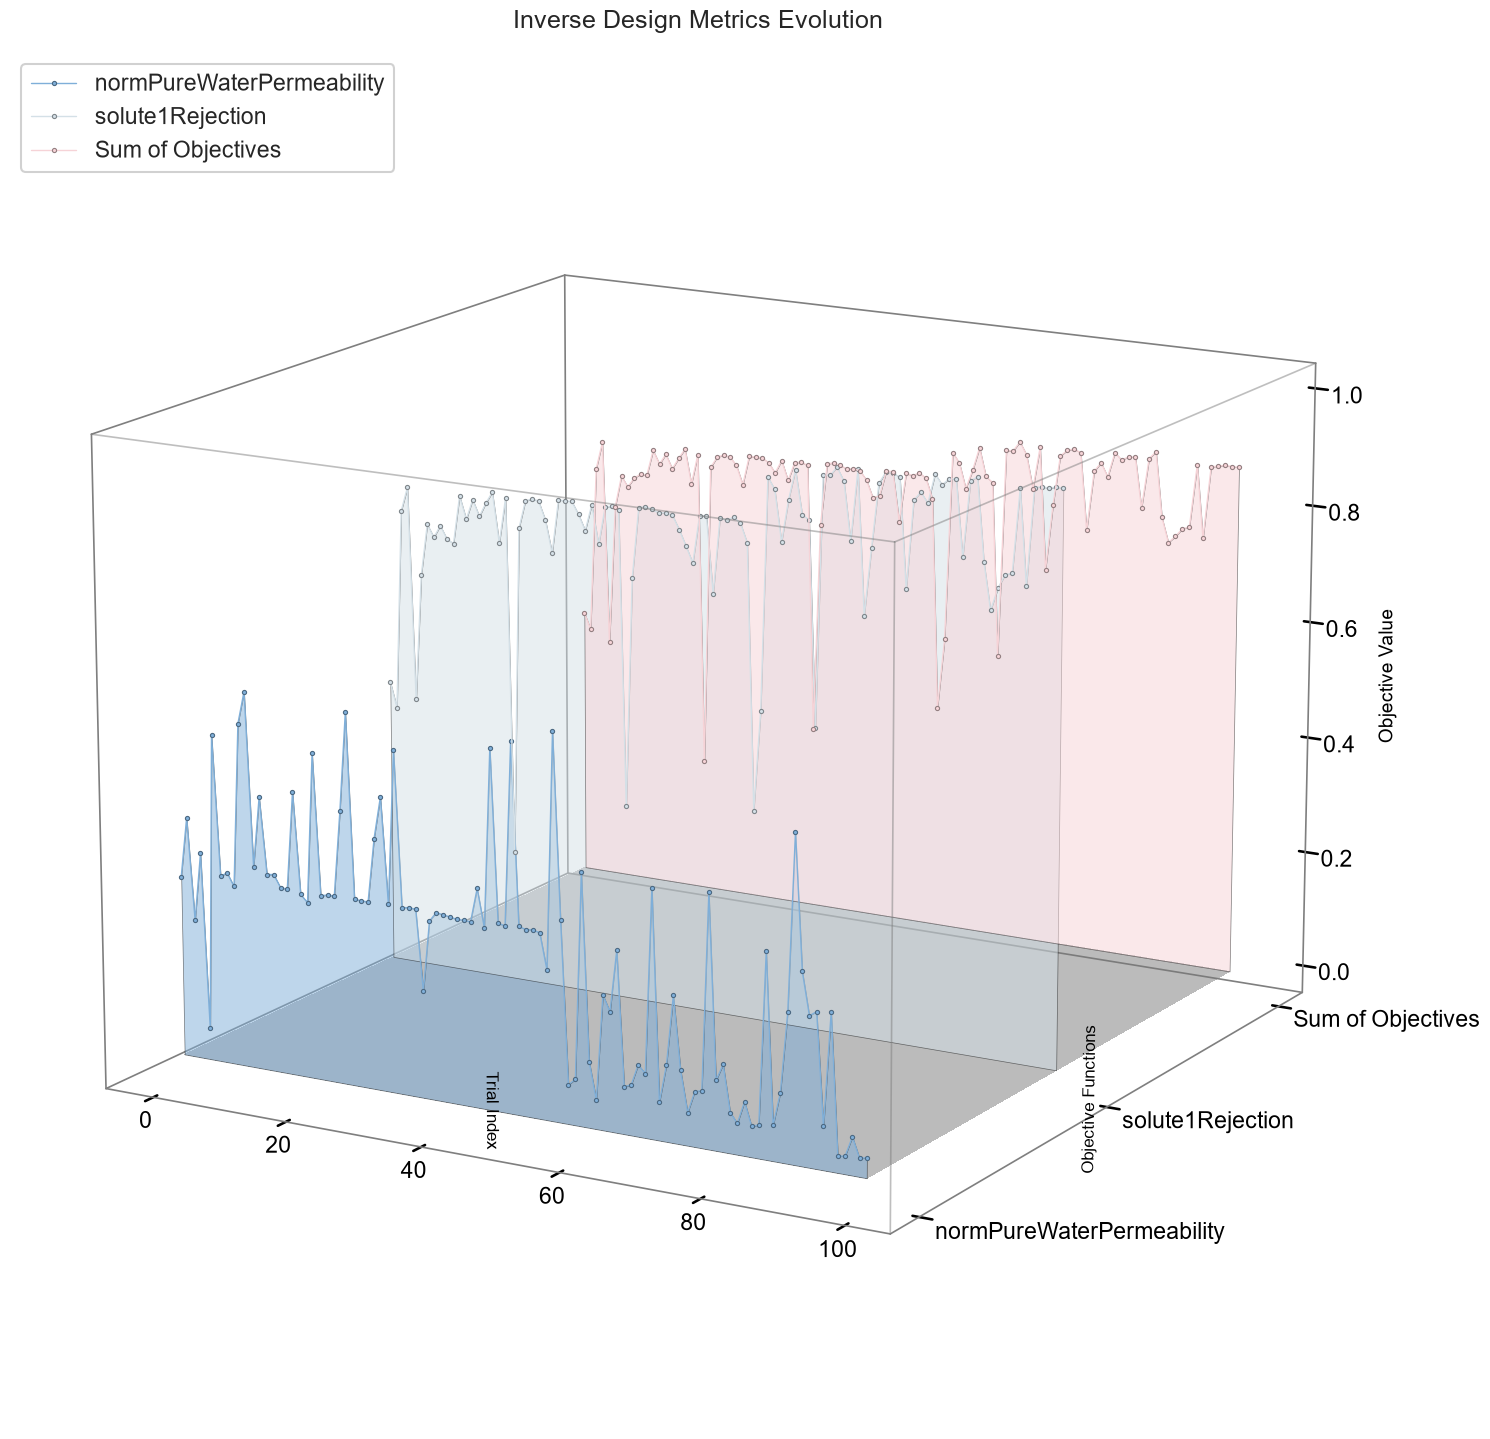

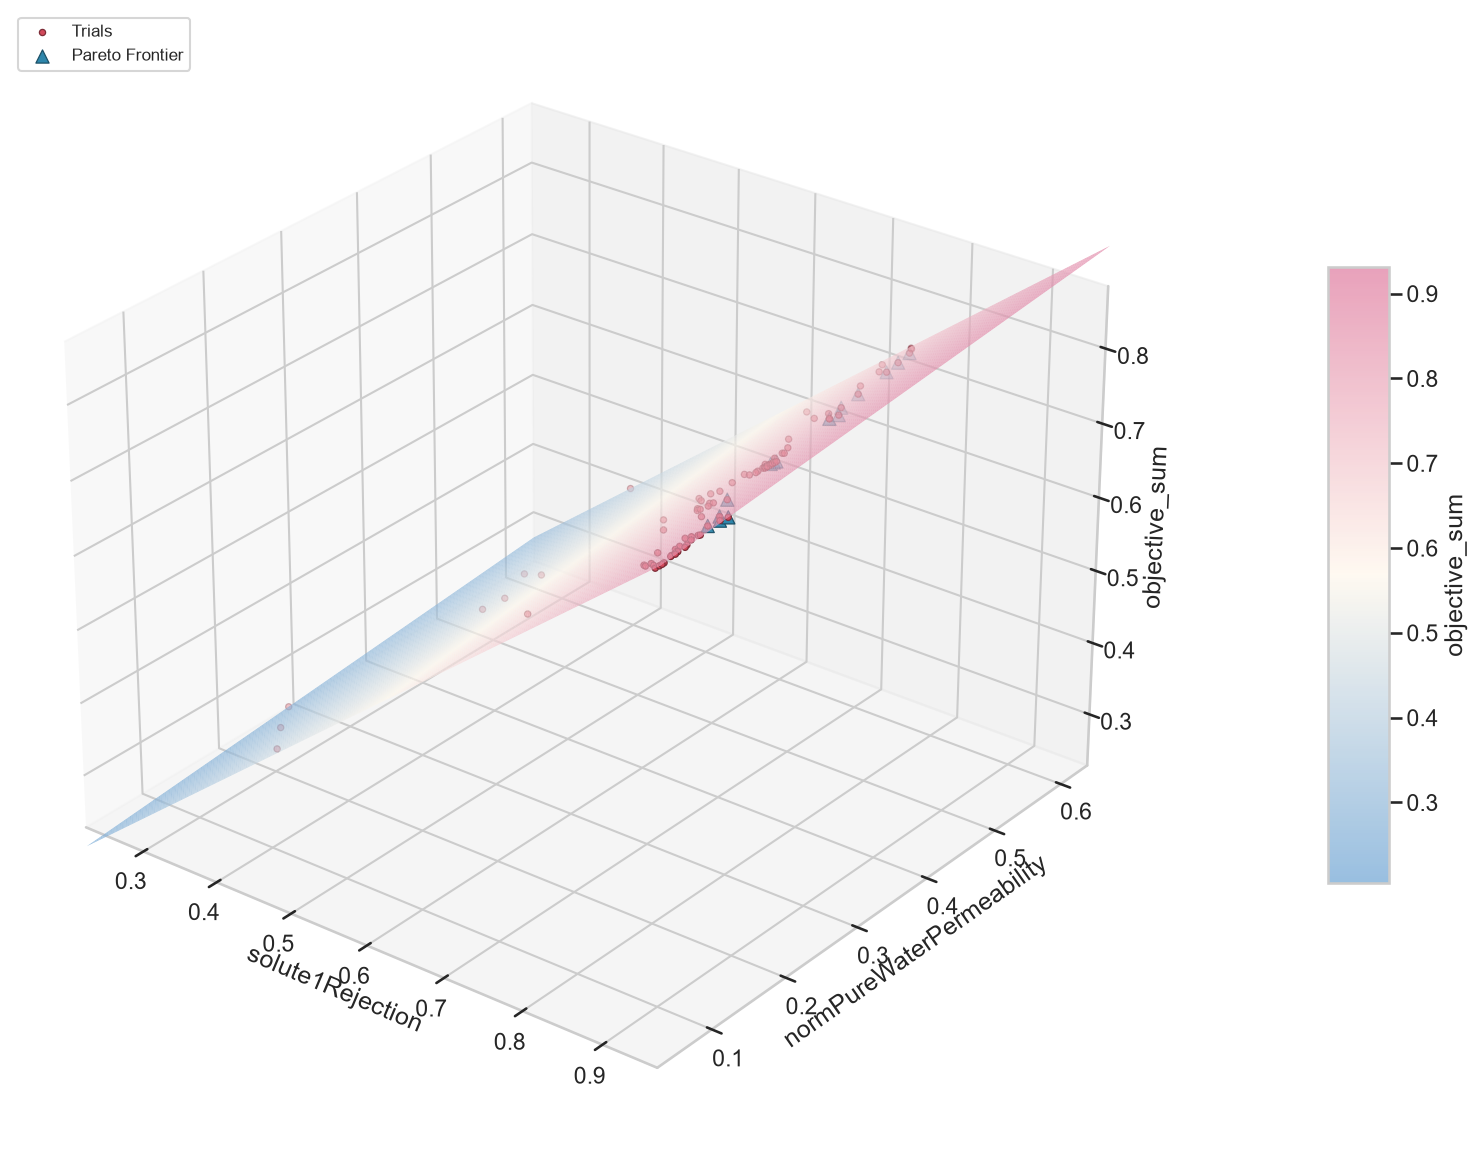

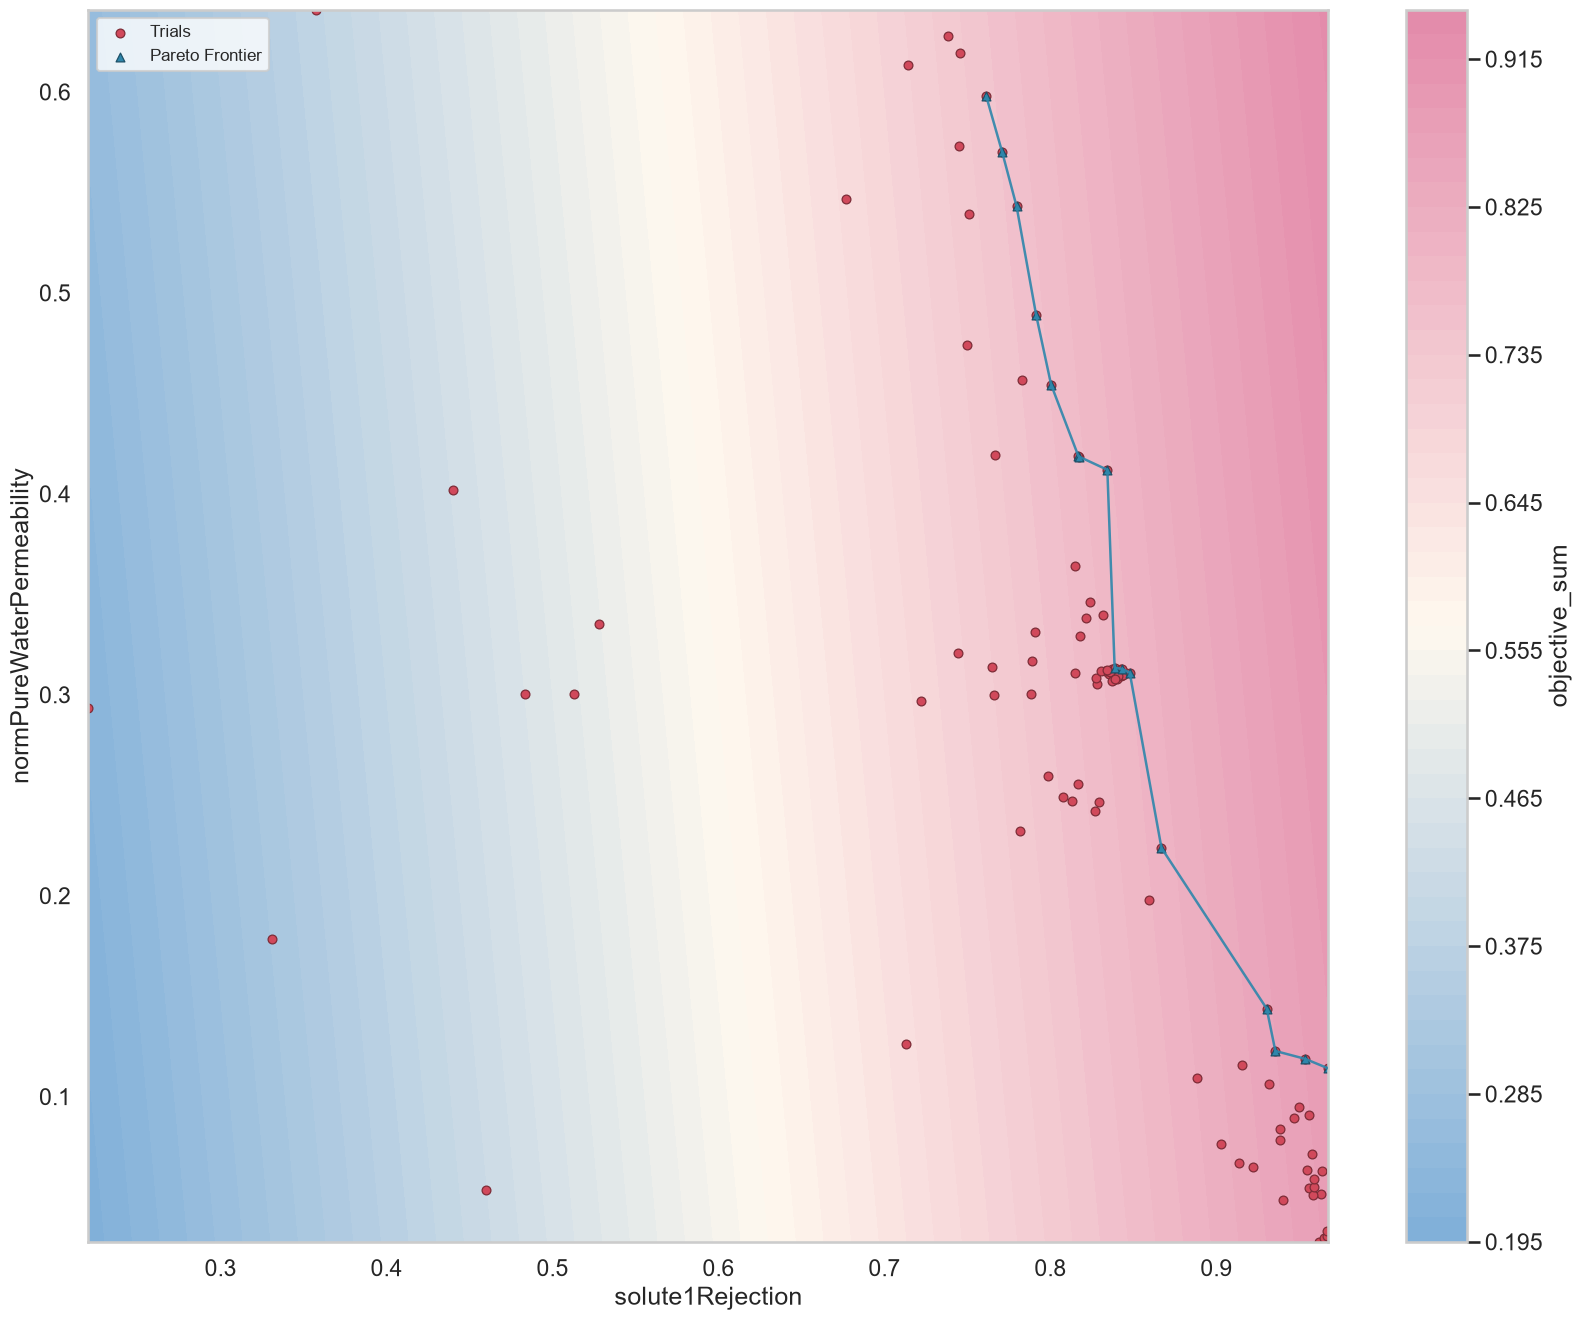

In [19]:
from utl_fileIO import file_io

trial_df = results_to_dataframe(results)

# Map weight_dict keys to the objective column names used in trial_df
objective_weights = {
    "normPureWaterPermeability": weight_dict["PureWaterPermeability"],
    "solute1Rejection": weight_dict["solute1Rejection"],
}

viz = plot_ax_results(
    trial_df=trial_df,
    objective_names=["normPureWaterPermeability", "solute1Rejection"],
    optimization_mode=OPTIMIZATION_MODE,
    client=client,
    objective_weights=objective_weights,
    fig_size=FIG_SIZE,
    response_map_specs=[
        {
            "x_col": "solute1Rejection",
            "y_col": "normPureWaterPermeability",
            "z_col": "objective_sum",
            "smoothing": 0.01,
            "surface_cmap": custom_cmap,
            "contour_cmap": custom_cmap,
            "trial_color": "#D1495B",
            "frontier_color": "#2E86AB",
            "surface_marker_size": 90,
            "contour_marker_size": 40,
            "elev": 28,
            "azim": -52,
            "fig_size": FIG_SIZE,
        }
    ],
)

history_df = viz["history_df"]
display(history_df)

# Save objective evolution figures
for name, fig in viz["figures"].items():
    if hasattr(fig, "savefig"):
        file_io("save", "figure", FIGURES_DIR, f"{name}.png", data=fig)

frontier_df = viz["frontier_df"]
display(frontier_df)

if viz["response_maps"]:
    response = viz["response_maps"][0]
    file_io("save", "figure", FIGURES_DIR, "inverse_design_surface.png", data=response["surface_figure"])
    file_io("save", "figure", FIGURES_DIR, "inverse_design_contour.png", data=response["contour_figure"])

print(f"\n??All inverse design visualizations saved to {FIGURES_DIR}")

## Section 7. Takeaways and next steps

This tutorial has walked through a complete, though compact, workflow for machine learning–assisted membrane development using a literature-derived dataset. Starting from heterogeneous experimental records, we constructed an enriched feature table, trained and evaluated a supervised model, interpreted its behavior with SHAP, and used the resulting surrogate for inverse design with Ax.

Key takeaways are:
- **Data representation matters:** Careful feature engineering that combines fabrication variables with physically meaningful solute descriptors (such as ionic size and charge) is essential for learning useful structure–process–performance relationships from limited experimental data.
- **Tree-based models are a strong baseline:** Ensemble methods like ExtraTrees provide robust performance on mixed tabular data, capture nonlinear interactions, and expose feature importances that can be linked back to membrane physics.
- **Interpretability and design should be coupled:** SHAP analysis helps distinguish physically plausible patterns from spurious correlations, while Bayesian optimization over a curated subset of controllable variables demonstrates how surrogate models can guide the search for promising new formulations.

At the same time, the workflow has important limitations: the model is trained on a relatively small, literature-curated dataset; extrapolation beyond the observed design space is uncertain; and the surrogate neglects measurement noise and experimental variability. Future extensions could include uncertainty quantification, more diverse descriptor sets (for polymers and solvents), and active-learning loops where new experiments are selected and incorporated into the training data.

Readers are encouraged to adapt this template to their own membrane systems: replace or extend the descriptors, swap in alternative model classes, and modify the inverse-design objective to reflect different application priorities (for example, weighted combinations of flux, rejec